# Task A1: Data Loading, EDA & Preprocessing

## Objective
Load the CIFAR-10 dataset, explore its structure and image classes,
visualize sample images, normalize pixel values, and one-hot encode
the target labels.

## Expected Output
- CIFAR-10 training and testing data loaded
- Dataset shapes and data types displayed
- 5 samples from each of the 10 classes visualized
- Pixel distribution before and after normalization
- Labels converted to one-hot encoded format
- Understanding of why CNNs are preferred over ANNs for images

## Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.16.1


# A1.1 Load CIFAR-10 

## Load CIFAR-10

In [3]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

print("CIFAR-10 dataset loaded successfully.")

CIFAR-10 dataset loaded successfully.


## Check Dataset Shapes

In [4]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


## Check Unique Labels and Data Type

In [5]:
print("Unique class labels:")
print(np.unique(y_train))

print("\nX_train dtype:", X_train.dtype)
print("X_test dtype:", X_test.dtype)

print("\nMinimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Unique class labels:
[0 1 2 3 4 5 6 7 8 9]

X_train dtype: uint8
X_test dtype: uint8

Minimum pixel value: 0
Maximum pixel value: 255


# A1.2 Visualise sample images 

## Define CIFAR-10 Class Names

In [6]:
class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

for i, name in enumerate(class_names):
    print(i, "=", name)

0 = Airplane
1 = Automobile
2 = Bird
3 = Cat
4 = Deer
5 = Dog
6 = Frog
7 = Horse
8 = Ship
9 = Truck


## Visualize 5 Samples per Class

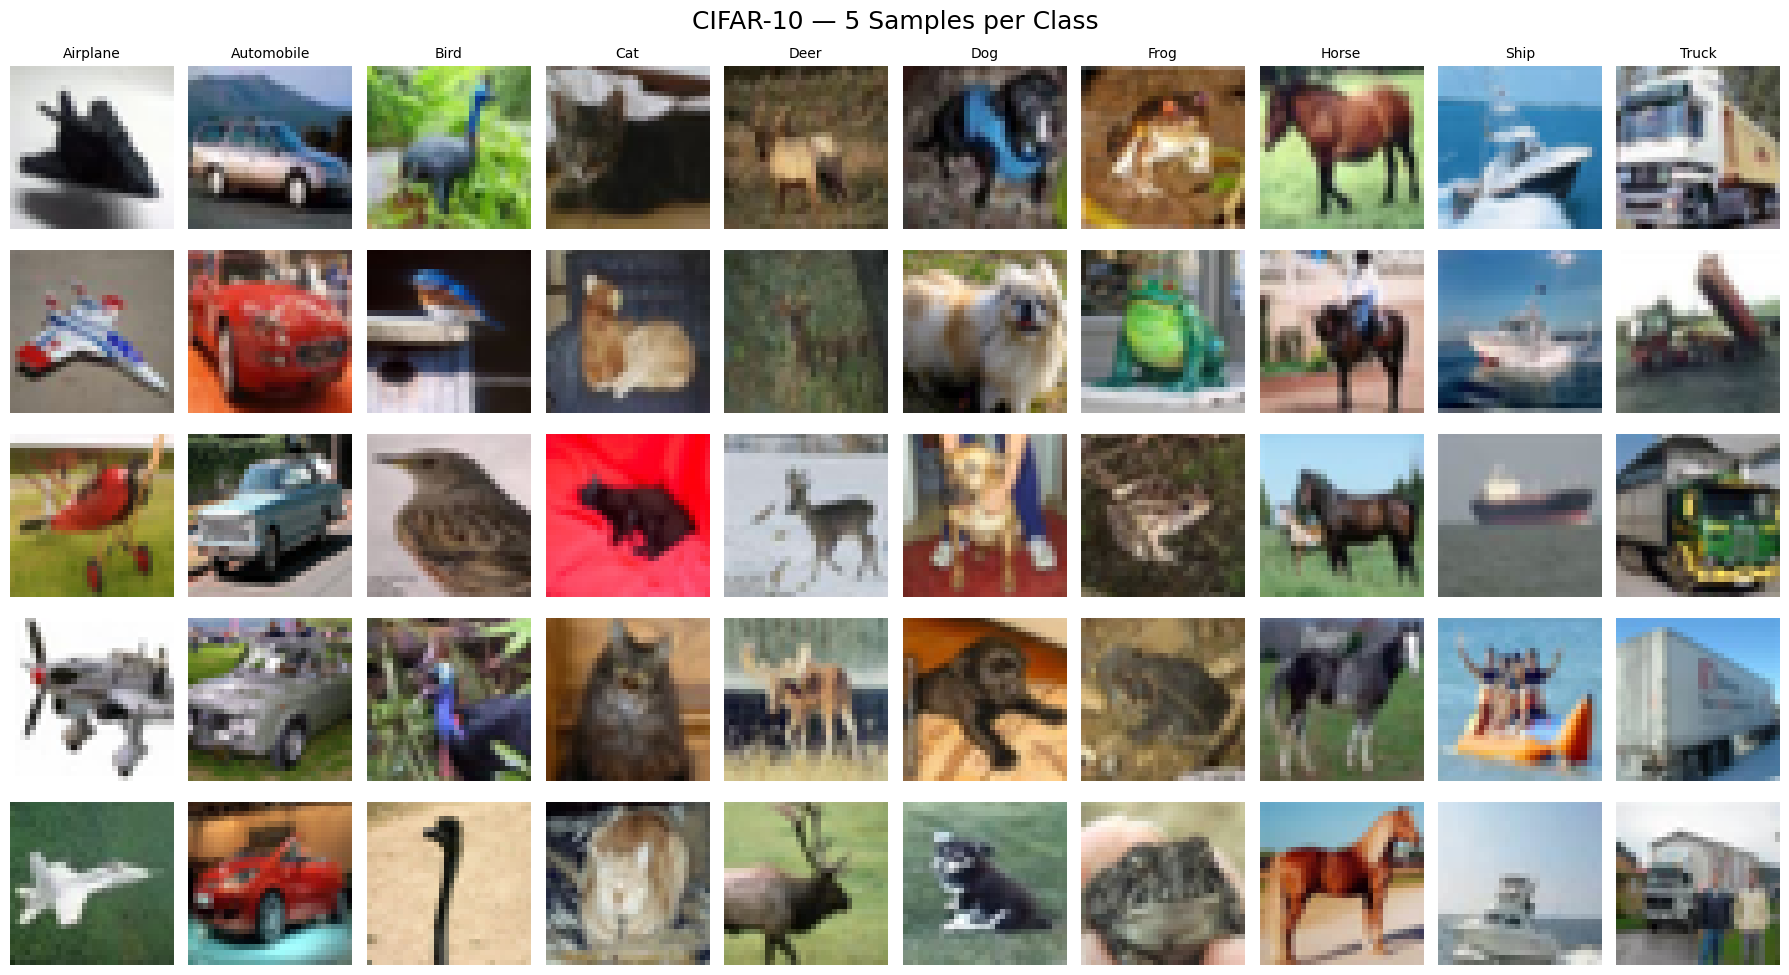

In [7]:
fig, axes = plt.subplots(5, 10, figsize=(18, 10))

for class_idx in range(10):
    
    indices = np.where(y_train.flatten() == class_idx)[0][:5]
    
    for row, image_idx in enumerate(indices):
        
        axes[row, class_idx].imshow(X_train[image_idx])
        axes[row, class_idx].axis("off")
        
        if row == 0:
            axes[row, class_idx].set_title(
                class_names[class_idx],
                fontsize=10
            )

plt.suptitle(
    "CIFAR-10 — 5 Samples per Class",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    "plots/cifar10_samples_grid.png",
    bbox_inches="tight"
)

plt.show()

### Observation — Visually Similar Classes

Some CIFAR-10 classes are visually similar, particularly:

- Cat and Dog
- Automobile and Truck

These class pairs are likely to be more difficult for the CNN to distinguish
because CIFAR-10 images have a very small resolution of only 32×32 pixels.

At this resolution, many fine visual details that distinguish similar objects
are lost.

# A1.3 — Pixel Distribution & Normalization

## Pixel Distribution Before Normalization

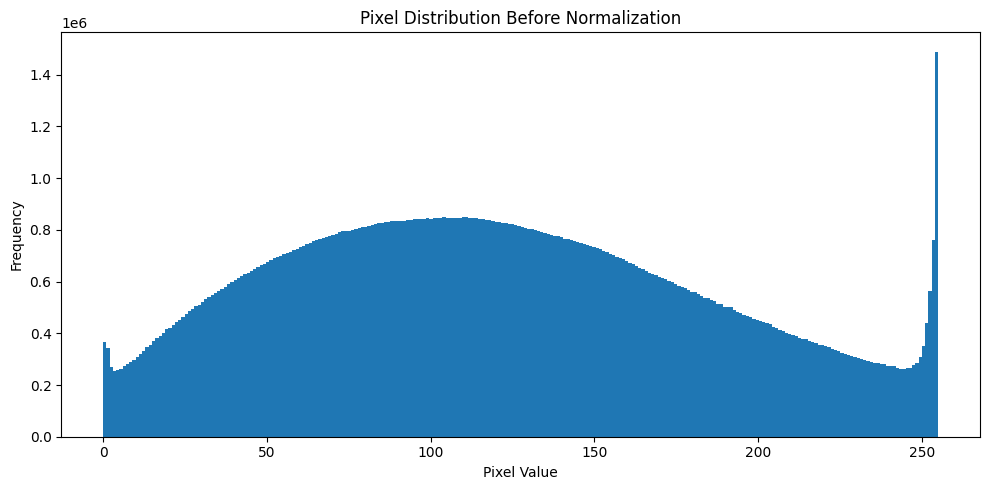

In [8]:
plt.figure(figsize=(10, 5))

plt.hist(
    X_train.flatten(),
    bins=256
)

plt.title("Pixel Distribution Before Normalization")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    "plots/pixel_histogram_before_normalization.png",
    
    bbox_inches="tight"
)

plt.show()


## Normalize Images

In [9]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Normalization completed.")

print("\nX_train dtype:", X_train.dtype)
print("X_test dtype:", X_test.dtype)

print("\nMinimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Normalization completed.

X_train dtype: float32
X_test dtype: float32

Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Pixel Distribution After Normalization

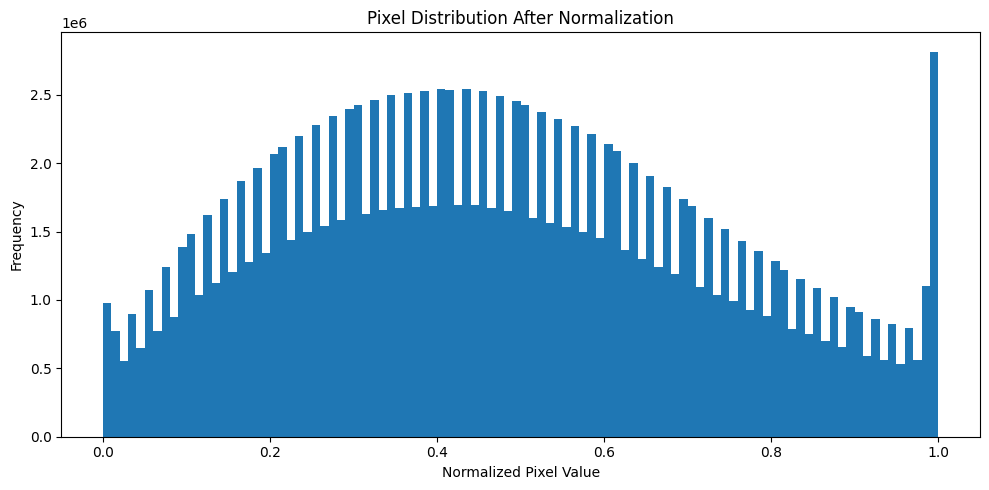

In [10]:
plt.figure(figsize=(10, 5))

plt.hist(
    X_train.flatten(),
    bins=100
)

plt.title("Pixel Distribution After Normalization")
plt.xlabel("Normalized Pixel Value")
plt.ylabel("Frequency")


plt.tight_layout()

plt.savefig(
    "plots/pixel_histogram_after_normalization.png",
    
    bbox_inches="tight"
)

plt.show()

### Why Do We Normalize Pixel Values?

The original CIFAR-10 images contain pixel values between 0 and 255.

We normalize the images using:

X = X / 255.0

This converts the pixel values to the range [0, 1].

Normalization helps gradient descent converge faster because the input values
are kept on a small and consistent scale. Large raw pixel values, up to 255,
can produce proportionally large initial weight updates and may destabilize
the early stages of model training.

# A1.4 — One-Hot Encoding

## One-Hot Encode Labels

In [11]:
y_train_ohe = keras.utils.to_categorical(y_train, 10)
y_test_ohe = keras.utils.to_categorical(y_test, 10)

print("Original y_train shape:", y_train.shape)
print("One-hot y_train shape:", y_train_ohe.shape)

print("\nOriginal label:")
print(y_train[0])

print("\nOne-hot encoded label:")
print(y_train_ohe[0])

Original y_train shape: (50000, 1)
One-hot y_train shape: (50000, 10)

Original label:
[6]

One-hot encoded label:
[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


### Why Use One-Hot Encoding?

The final output layer of the CNN will use the Softmax activation function.

Softmax produces a probability distribution over the 10 CIFAR-10 classes.

For example:

[0.01, 0.02, 0.80, 0.03, ...]

One-hot encoding converts the correct class into a vector such as:

[0, 0, 1, 0, 0, 0, 0, 0, 0, 0]

This allows `categorical_crossentropy` to compare the predicted probability
distribution with the one-hot encoded ground-truth label.

If integer labels were used instead, we would use
`sparse_categorical_crossentropy`.

# A1.5 — CNN vs ANN

# CNN vs ANN for Image Classification

## 1. ANN (MLP)

A traditional Artificial Neural Network normally flattens an image into a
one-dimensional vector.

For a CIFAR-10 image:

32 × 32 × 3 → 3072 values

Flattening removes the original spatial relationships between neighbouring
pixels.

Therefore, the ANN does not naturally understand that nearby pixels may form
edges, textures, shapes, or object parts.

---

## 2. CNN

A Convolutional Neural Network keeps the spatial structure of the image.

It applies small learnable filters (kernels) that slide across the image.

For example, a 3×3 kernel examines small local regions of the image and can
learn patterns such as:

- edges
- colours
- gradients
- textures
- shapes

The same filter is applied at different locations in the image. This helps the
CNN detect a feature regardless of where it appears, providing translation
invariance.

---

## 3. Parameter Sharing

CNNs use parameter sharing.

For example, a 3×3 filter contains only 9 spatial weights per input channel,
and the same weights are reused while the filter slides across the image.

For a 32×32 image with VALID convolution, the 3×3 filter can be applied across
30×30 spatial positions while reusing the same kernel weights.

In contrast, a fully connected ANN uses separate weights for its individual
connections.

Therefore, CNNs generally require far fewer parameters for spatial feature
extraction and are much better suited for image classification.

# Task A2: Convolution Operation, Padding & Strides

## Objective
Understand how convolution works manually and study the effects of padding
and strides on CNN feature maps.

## Expected Output
- Manual convolution using a 3×3 edge-detection kernel
- Comparison of VALID and SAME padding
- Comparison of stride = 1 and stride = 2
- Visualization of 16 feature maps produced by a Conv2D layer

# A2.1 — Manual Convolution Demo

# Import SciPy

In [12]:
from scipy.signal import convolve2d

print("SciPy convolve2d imported successfully.")

SciPy convolve2d imported successfully.


## Convert One CIFAR-10 Image to Grayscale

In [13]:
# Select the first CIFAR-10 image
sample_image = X_train[0]

# Convert RGB image to grayscale
gray = np.mean(sample_image, axis=2)

print("Original RGB image shape:", sample_image.shape)
print("Grayscale image shape:", gray.shape)

Original RGB image shape: (32, 32, 3)
Grayscale image shape: (32, 32)


## Define 3×3 Edge Detection Kernel

In [14]:
kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

print("Edge Detection Kernel:")
print(kernel)

print("\nKernel shape:", kernel.shape)

Edge Detection Kernel:
[[-1 -1 -1]
 [-1  8 -1]
 [-1 -1 -1]]

Kernel shape: (3, 3)


## Apply Manual Convolution

In [15]:
convolved_image = convolve2d(
    gray,
    kernel,
    mode="valid"
)

print("Original grayscale shape:", gray.shape)
print("Convolved output shape:", convolved_image.shape)

Original grayscale shape: (32, 32)
Convolved output shape: (30, 30)


## Display Original and Convolved Image

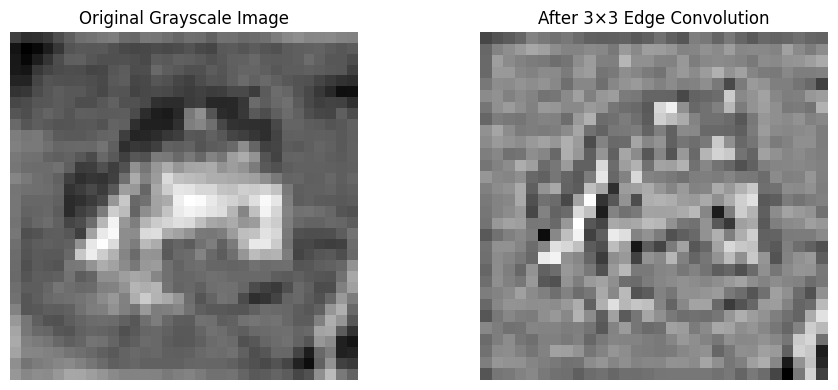

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original Grayscale Image")
axes[0].axis("off")

axes[1].imshow(convolved_image, cmap="gray")
axes[1].set_title("After 3×3 Edge Convolution")
axes[1].axis("off")



plt.tight_layout()

plt.savefig(
    "plots/manual_convolution_edge_detection.png",
    
    bbox_inches="tight"
)

plt.show()

### How Does Convolution Work?

The convolution operation computes a dot product between the kernel and each
overlapping patch of the input image.

The 3×3 kernel slides across the image one step at a time. At every position,
the kernel values are multiplied by the corresponding image pixel values and
the results are summed.

Each result becomes one value in the new feature map.

In this example, the edge-detection kernel responds strongly to regions where
pixel intensity changes sharply, helping highlight edges.

This is the same basic operation performed by CNN Conv2D layers. The main
difference is that CNN kernel weights are learned automatically during
training and operate across the image channels.

# A2.2 — Padding: VALID vs SAME

## VALID Padding Model

In [17]:
valid_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(
        filters=8,
        kernel_size=(3, 3),
        strides=1,
        padding="valid"
    )
])

print("VALID Padding Output Shape:")
print(valid_model.output_shape)

VALID Padding Output Shape:
(None, 30, 30, 8)


## SAME Padding Model

In [18]:
same_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(
        filters=8,
        kernel_size=(3, 3),
        strides=1,
        padding="same"
    )
])

print("SAME Padding Output Shape:")
print(same_model.output_shape)

SAME Padding Output Shape:
(None, 32, 32, 8)


## Compare VALID vs SAME

In [19]:
print("Input Shape:")
print((32, 32, 3))

print("\nVALID Padding:")
print("Output Shape =", valid_model.output_shape)

print("\nSAME Padding:")
print("Output Shape =", same_model.output_shape)

# VALID convolution output formula
input_size = 32
kernel_size = 3
stride = 1

valid_output = ((input_size - kernel_size) // stride) + 1

print("\nVALID Output Size Formula:")
print("(Input - Kernel) / Stride + 1")
print(f"({input_size} - {kernel_size}) / {stride} + 1 = {valid_output}")

Input Shape:
(32, 32, 3)

VALID Padding:
Output Shape = (None, 30, 30, 8)

SAME Padding:
Output Shape = (None, 32, 32, 8)

VALID Output Size Formula:
(Input - Kernel) / Stride + 1
(32 - 3) / 1 + 1 = 30


## Display Zero-Padded Image

Original shape: (32, 32)
Padded shape: (34, 34)


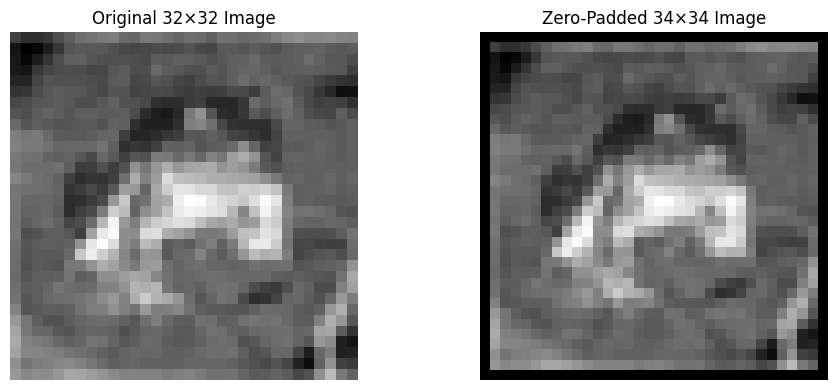

In [20]:
# Pad grayscale image by 1 pixel on every side
padded_gray = np.pad(
    gray,
    pad_width=1,
    mode="constant",
    constant_values=0
)

print("Original shape:", gray.shape)
print("Padded shape:", padded_gray.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original 32×32 Image")
axes[0].axis("off")

axes[1].imshow(padded_gray, cmap="gray")
axes[1].set_title("Zero-Padded 34×34 Image")
axes[1].axis("off")



plt.tight_layout()

plt.savefig(
    "plots/zero_padding_visualization.png",
    
    bbox_inches="tight"
)

plt.show()

### VALID vs SAME Padding

**VALID padding** does not add extra pixels around the image.

For a 32×32 input, 3×3 kernel and stride 1:

Output Size = (32 - 3) / 1 + 1 = 30

Therefore:

32×32 → 30×30

**SAME padding** adds zero-padding around the border so that the spatial
dimensions can be preserved when stride = 1.

Therefore:

32×32 → 32×32

SAME padding is commonly used in CNN architectures because it allows many
convolutional layers to be stacked without reducing the spatial dimensions
too quickly.

# A2.3 — Effect of Strides

## Stride = 1

In [21]:
stride1_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(
        8,
        kernel_size=(3, 3),
        strides=1,
        padding="same"
    )
])

print("Stride = 1")
print("Input shape :", (32, 32, 3))
print("Output shape:", stride1_model.output_shape)

Stride = 1
Input shape : (32, 32, 3)
Output shape: (None, 32, 32, 8)


## Stride = 2

In [22]:
stride2_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(
        8,
        kernel_size=(3, 3),
        strides=2,
        padding="same"
    )
])

print("Stride = 2")
print("Input shape :", (32, 32, 3))
print("Output shape:", stride2_model.output_shape)

Stride = 2
Input shape : (32, 32, 3)
Output shape: (None, 16, 16, 8)


## Compare Strides

In [23]:
print("STRIDE COMPARISON")
print("-" * 40)

print("Stride = 1")
print("Output:", stride1_model.output_shape)

print("\nStride = 2")
print("Output:", stride2_model.output_shape)

print("\nSpatial size:")
print("32×32 → 32×32 with stride 1")
print("32×32 → 16×16 with stride 2")

STRIDE COMPARISON
----------------------------------------
Stride = 1
Output: (None, 32, 32, 8)

Stride = 2
Output: (None, 16, 16, 8)

Spatial size:
32×32 → 32×32 with stride 1
32×32 → 16×16 with stride 2


### Effect of Stride

Stride controls how many pixels the convolution filter moves at each step.

**Stride = 1**

The filter moves one pixel at a time. This produces a dense feature map and,
with SAME padding, preserves the 32×32 spatial dimensions.

**Stride = 2**

The filter moves two pixels at a time. This reduces the spatial dimensions:

32×32 → 16×16

Therefore, stride 2 performs downsampling.

Strided convolution can be used as an alternative to pooling because the
downsampling operation is performed using learnable convolution filters
rather than a fixed pooling operation.

# A2.4 — Build and Visualize Feature Maps

## Create Conv2D Visualization Model

In [24]:
model_vis = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    
    layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    )
])

model_vis.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448 (1.75 KB)

 Trainable params: 448 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

## Generate 16 Feature Maps

In [25]:
# Select one image
img = X_train[0]

# Add batch dimension
img_batch = np.expand_dims(img, axis=0)

print("Original image shape:", img.shape)
print("Batch input shape:", img_batch.shape)

# Pass image through Conv2D layer
feature_maps = model_vis.predict(img_batch, verbose=0)

print("Feature maps shape:", feature_maps.shape)

Original image shape: (32, 32, 3)
Batch input shape: (1, 32, 32, 3)
Feature maps shape: (1, 32, 32, 16)


## Display Original Image

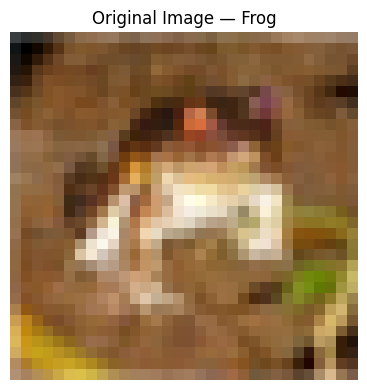

In [26]:
plt.figure(figsize=(4, 4))

plt.imshow(img)
plt.title(
    f"Original Image — {class_names[y_train[0][0]]}"
)
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "plots/feature_map_original_image.png",
    
    bbox_inches="tight"
)

plt.show()


## Display All 16 Feature Maps

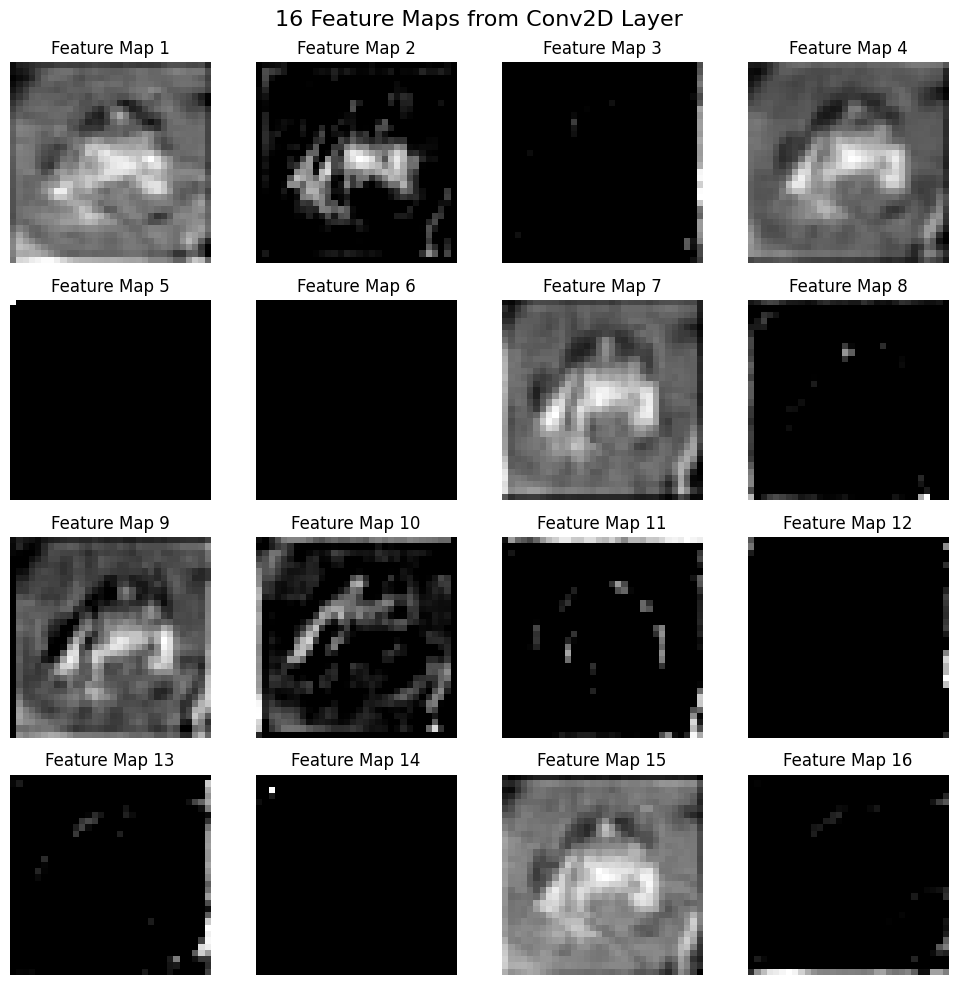

In [27]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    
    ax.imshow(
        feature_maps[0, :, :, i],
        cmap="gray"
    )
    
    ax.set_title(f"Feature Map {i + 1}")
    ax.axis("off")

plt.suptitle(
    "16 Feature Maps from Conv2D Layer",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "plots/feature_maps.png",
    
    bbox_inches="tight"
)

plt.show()

### Understanding Feature Maps

Each feature map represents the response produced by one learnable
convolution filter.

The Conv2D layer used here contains 16 filters, so it produces 16 different
feature maps.

Different filters can respond to different visual patterns in an image.

Early CNN layers generally learn simple features such as:

- edges
- colour changes
- gradients
- simple textures

As we move deeper into a CNN, the learned features become progressively more
complex and may represent:

- textures
- shapes
- object parts
- higher-level visual patterns

Therefore, convolutional layers automatically learn useful visual features
from the training data.

# Task A3: Pooling, MaxPooling, Flatten & CNN Architecture

## Objective
Understand pooling operations and the Flatten layer, implement the historical
LeNet-5 architecture, and build a modern CNN architecture for CIFAR-10.

## Expected Output
- Compare feature maps before and after MaxPooling
- Compare MaxPooling and AveragePooling
- Demonstrate Flatten operation
- Implement LeNet-5 for CIFAR-10
- Manually verify parameter counts
- Build a modern custom CNN with fewer than 2 million parameters

# A3.1 — MaxPooling vs AveragePooling

## Create MaxPooling Model

In [28]:
maxpool_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2)
    )
])

maxpool_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448 (1.75 KB)

 Trainable params: 448 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

## Generate Feature Maps Before and After MaxPooling

In [29]:
# Feature maps before pooling
feature_maps_before = model_vis.predict(
    img_batch,
    verbose=0
)

# Feature maps after MaxPooling
feature_maps_max = maxpool_model.predict(
    img_batch,
    verbose=0
)

print("Before MaxPooling:", feature_maps_before.shape)
print("After MaxPooling :", feature_maps_max.shape)

Before MaxPooling: (1, 32, 32, 16)
After MaxPooling : (1, 16, 16, 16)


## Display Feature Maps Before MaxPooling

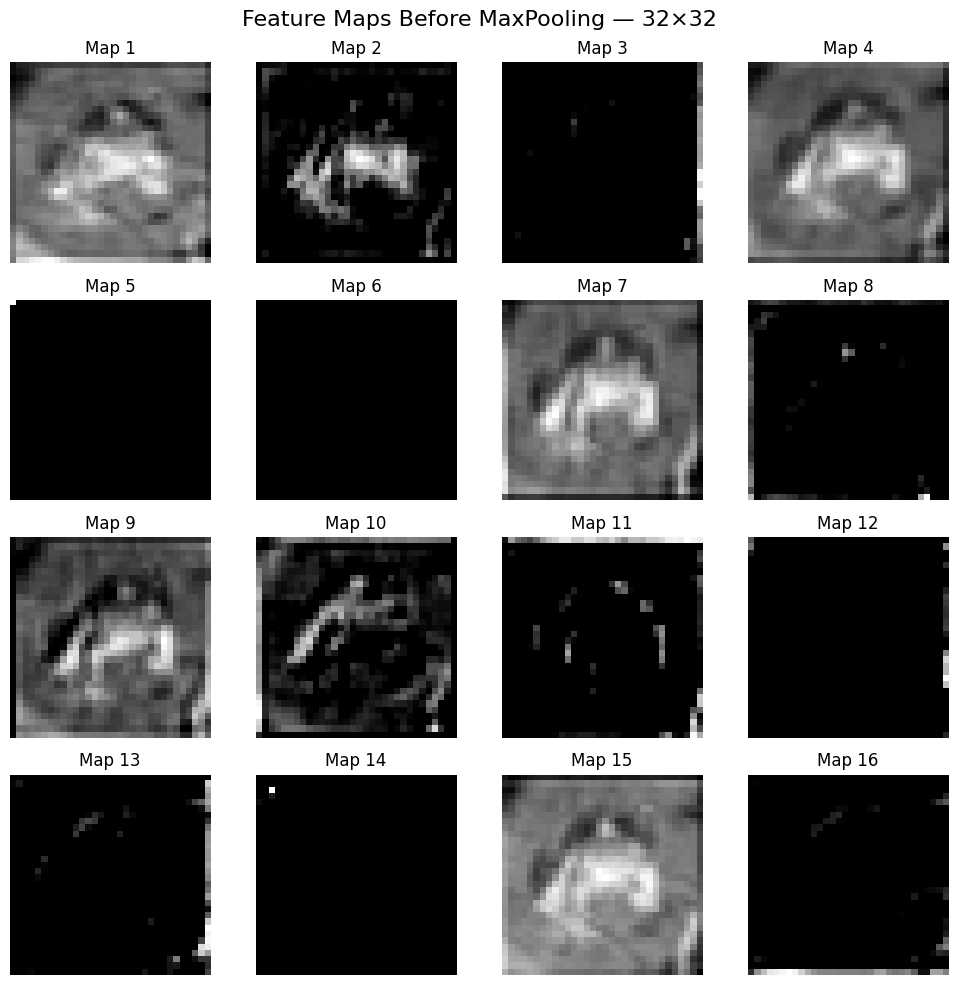

In [30]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        feature_maps_before[0, :, :, i],
        cmap="gray"
    )

    ax.set_title(f"Map {i + 1}")
    ax.axis("off")

plt.suptitle(
    "Feature Maps Before MaxPooling — 32×32",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "plots/feature_maps_before_pooling.png",
    
    bbox_inches="tight"
)

plt.show()


## Display Feature Maps After MaxPooling

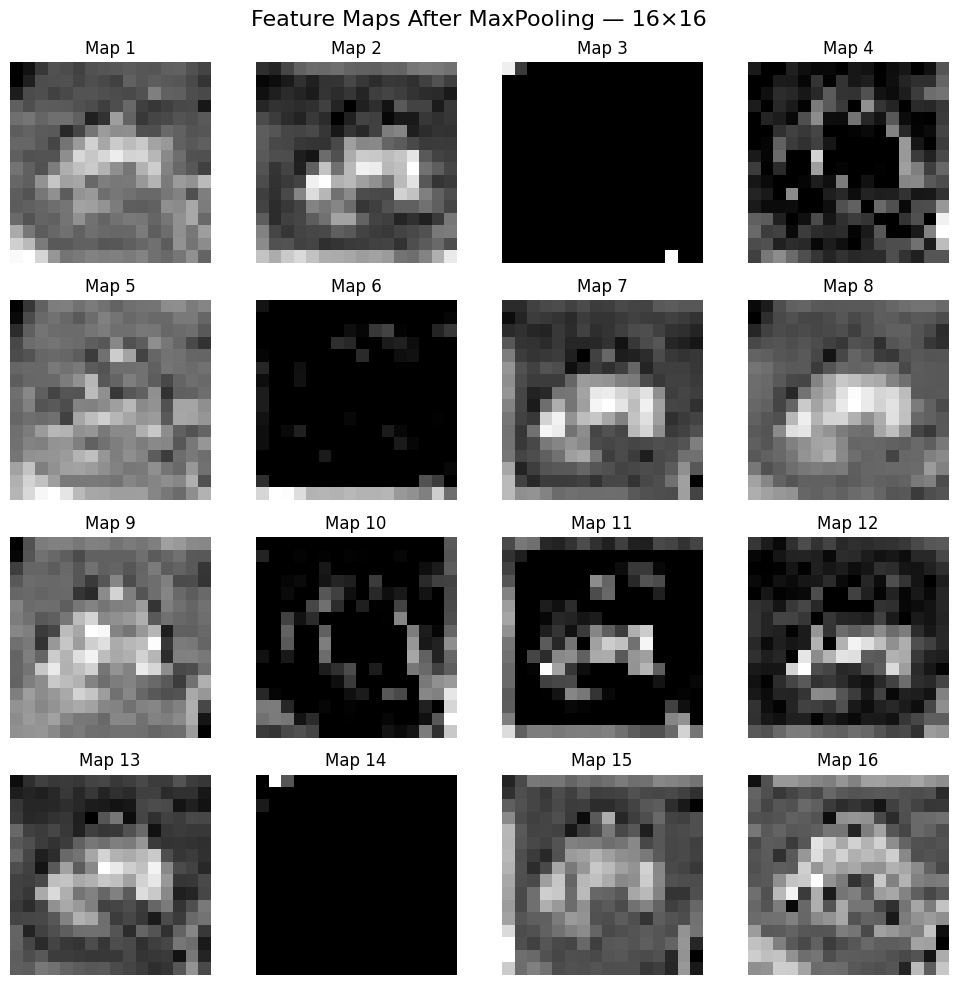

In [31]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        feature_maps_max[0, :, :, i],
        cmap="gray"
    )

    ax.set_title(f"Map {i + 1}")
    ax.axis("off")

plt.suptitle(
    "Feature Maps After MaxPooling — 16×16",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "plots/maxpooling_feature_maps.png",
    
    bbox_inches="tight"
)

plt.show()

## Create AveragePooling Model

In [32]:
avgpool_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.AveragePooling2D(
        pool_size=(2, 2)
    )
])

feature_maps_avg = avgpool_model.predict(
    img_batch,
    verbose=0
)

print("Before Pooling :", feature_maps_before.shape)
print("After AvgPooling:", feature_maps_avg.shape)

Before Pooling : (1, 32, 32, 16)
After AvgPooling: (1, 16, 16, 16)


## Display AveragePooling Feature Maps

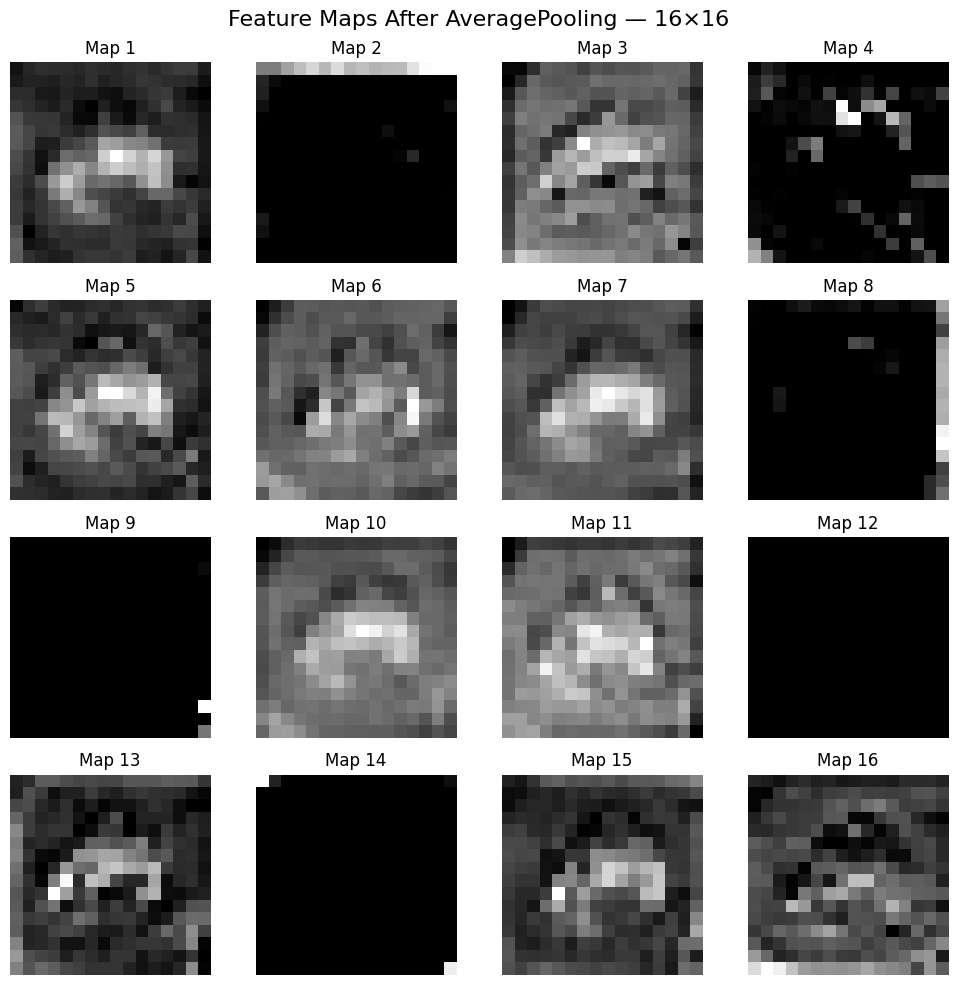

In [33]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        feature_maps_avg[0, :, :, i],
        cmap="gray"
    )

    ax.set_title(f"Map {i + 1}")
    ax.axis("off")

plt.suptitle(
    "Feature Maps After AveragePooling — 16×16",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "plots/averagepooling_feature_maps.png",
    
    bbox_inches="tight"
)

plt.show()

### MaxPooling vs AveragePooling

#### MaxPooling2D

MaxPooling2D(2,2) examines each 2×2 region and keeps only the maximum
activation.

It therefore preserves the strongest or most prominent detected feature.

For example:

32×32 → MaxPooling(2×2) → 16×16

MaxPooling also provides a small amount of translation invariance because
small movements of a feature may still produce the same maximum value.

#### AveragePooling2D

AveragePooling calculates the average value of each 2×2 region.

It produces smoother feature maps and preserves more general spatial
information, but the strongest activations are less prominent.

#### GlobalAveragePooling2D

Modern CNN architectures often use GlobalAveragePooling2D instead of Flatten.

GlobalAveragePooling2D averages every feature map into one value. This
dramatically reduces the number of parameters required by the classification
head.

# A3.2 — Flatten Layer

## Create Conv + MaxPool + Flatten Model

In [34]:
flatten_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    layers.Flatten()
])

flatten_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448 (1.75 KB)

 Trainable params: 448 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

## Check Shape Before and After Flatten

In [35]:
shape_before_flatten = feature_maps_max.shape

flatten_output = flatten_model.predict(
    img_batch,
    verbose=0
)

print("Shape before Flatten:", shape_before_flatten)
print("Shape after Flatten :", flatten_output.shape)

print("\nCalculation:")
print("16 × 16 × 16 =", 16 * 16 * 16)

Shape before Flatten: (1, 16, 16, 16)
Shape after Flatten : (1, 4096)

Calculation:
16 × 16 × 16 = 4096


### Flatten Layer

The Flatten layer converts a three-dimensional feature tensor `(H, W, C)`
into a one-dimensional vector.

For example:

16 × 16 × 16 = 4096

Therefore:

(16, 16, 16) → (4096)

This allows convolutional feature maps to be connected to traditional Dense
classification layers.

The flattened size directly affects the number of parameters in the first
Dense layer.

Therefore, reducing spatial dimensions using pooling before Flatten is
important for keeping the number of model parameters manageable.

# A3.3 — LeNet-5 Architecture

## Build LeNet-5

In [36]:
model_lenet = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    layers.Conv2D(
        filters=6,
        kernel_size=(5, 5),
        activation="tanh"
    ),

    layers.AveragePooling2D(
        pool_size=(2, 2)
    ),

    layers.Conv2D(
        filters=16,
        kernel_size=(5, 5),
        activation="tanh"
    ),

    layers.AveragePooling2D(
        pool_size=(2, 2)
    ),

    layers.Flatten(),

    layers.Dense(
        120,
        activation="tanh"
    ),

    layers.Dense(
        84,
        activation="tanh"
    ),

    layers.Dense(
        10,
        activation="softmax"
    )
])

model_lenet.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

## Manually Calculate Conv2D Layer 1 Parameters

In [37]:
conv1_params = (5 * 5 * 3 + 1) * 6

print("Conv2D Layer 1")
print("----------------")

print("(5 × 5 × 3 + 1) × 6")
print("Parameters =", conv1_params)

Conv2D Layer 1
----------------
(5 × 5 × 3 + 1) × 6
Parameters = 456


## Manually Calculate Conv2D Layer 2 Parameters

In [38]:
conv2_params = (5 * 5 * 6 + 1) * 16

print("Conv2D Layer 2")
print("----------------")

print("(5 × 5 × 6 + 1) × 16")
print("Parameters =", conv2_params)

Conv2D Layer 2
----------------
(5 × 5 × 6 + 1) × 16
Parameters = 2416


## Verify Against Keras

In [39]:
print("Manual Parameter Verification")
print("=" * 40)

print(
    "Conv2D Layer 1 manual parameters:",
    conv1_params
)

print(
    "Conv2D Layer 1 Keras parameters :",
    model_lenet.layers[0].count_params()
)

print()

print(
    "Conv2D Layer 2 manual parameters:",
    conv2_params
)

print(
    "Conv2D Layer 2 Keras parameters :",
    model_lenet.layers[2].count_params()
)

Manual Parameter Verification
Conv2D Layer 1 manual parameters: 456
Conv2D Layer 1 Keras parameters : 456

Conv2D Layer 2 manual parameters: 2416
Conv2D Layer 2 Keras parameters : 2416


### LeNet-5 Architecture

LeNet-5 was one of the earliest successful Convolutional Neural Networks.

It was introduced by Yann LeCun and collaborators and was used for
handwritten character recognition, including postal codes and cheque
processing.

Its architecture established the important CNN pattern:

Conv → Pool → Conv → Pool → Flatten → Dense → Dense

Compared with many modern CNN architectures, LeNet-5:

1. Uses `tanh` instead of ReLU.
2. Uses AveragePooling instead of MaxPooling.
3. Uses 5×5 convolution filters, while many modern CNNs prefer stacked
   3×3 filters.

Despite its simplicity, LeNet-5 played an important historical role in the
development of modern convolutional neural networks.

# A3.4 — Custom Modern CNN for CIFAR-10

## Build Custom CNN

In [40]:
model_cnn = keras.Sequential([
    
    keras.Input(shape=(32, 32, 3)),

    # Block 1
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Block 2
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Block 3
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    # Global pooling
    layers.GlobalAveragePooling2D(),

    # Classification head
    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dense(
        10,
        activation="softmax"
    )
])

model_cnn.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

## Verify Parameter Count

In [41]:
total_params = model_cnn.count_params()

print("Total Parameters:", f"{total_params:,}")

if total_params < 2_000_000:
    print("PASS: Model contains fewer than 2 million parameters.")
else:
    print("FAIL: Model contains more than 2 million parameters.")

Total Parameters: 175,018
PASS: Model contains fewer than 2 million parameters.


## Check Model Input and Output

In [42]:
print("Custom CNN Architecture")
print("=" * 45)

print("Input shape :", model_cnn.input_shape)
print("Output shape:", model_cnn.output_shape)
print("Parameters  :", f"{model_cnn.count_params():,}")

print("\nNumber of output classes:")
print(model_cnn.output_shape[-1])

Custom CNN Architecture
Input shape : (None, 32, 32, 3)
Output shape: (None, 10)
Parameters  : 175,018

Number of output classes:
10


### Why Stack Two Convolution Layers Before Pooling?

The first convolution layer learns relatively simple visual features such as
edges, gradients and colour patterns.

The second convolution layer combines these simple features into slightly
more complex patterns.

Only after learning these richer representations do we reduce the spatial
resolution using MaxPooling.

Therefore, stacking multiple convolution layers before pooling gives the
network a richer feature hierarchy at each spatial scale.

The custom CNN follows the general pattern:

Conv → Conv → Pool → Conv → Conv → Pool → Conv → GlobalAveragePooling → Dense

GlobalAveragePooling is used instead of Flatten to significantly reduce the
number of parameters in the classification head.

# Task A4: Backpropagation in CNN & Training

## Objective
Understand how backpropagation works through convolution, pooling and
Flatten layers, then train and evaluate the custom CIFAR-10 CNN.

## Expected Output
- Explanation of CNN forward and backward propagation
- CNN trained using Adam and categorical crossentropy
- EarlyStopping and ReduceLROnPlateau callbacks
- Training and validation loss/accuracy curves
- Test accuracy
- 10×10 confusion matrix
- Top 3 most-confused class pairs
- 10 misclassified CIFAR-10 images

## Backpropagation in CNN

### 1. Forward Pass

During the forward pass, information moves through the CNN as:

Input Image
→ Convolution
→ Activation
→ Pooling
→ Convolution
→ Activation
→ Pooling
→ Classification Head
→ Softmax
→ Loss

Convolutional layers extract visual features while pooling layers reduce
spatial dimensions. The final layers produce probabilities for the 10
CIFAR-10 classes.

### 2. Backward Pass

During backpropagation, gradients of the loss are propagated backwards
through the network.

For Dense layers, the process is the same as standard ANN backpropagation.

For convolutional layers, the gradient of the loss is calculated with
respect to every element of every learnable kernel.

This is done by correlating the upstream gradient with the corresponding
local input patches.

The optimizer then updates the convolution kernel weights to reduce the loss.

### 3. Gradient Through MaxPooling

MaxPooling keeps only the maximum value from each pooling region during
the forward pass.

During backpropagation, only the position that produced the maximum value
receives the upstream gradient.

All other positions in that pooling region receive zero gradient.

This is known as the:

**Max Location Switch / Max Index Mask**

### 4. Gradient Through AveragePooling

AveragePooling calculates the average of all values in a pooling region.

During backpropagation, the upstream gradient is divided equally among
all positions in that pooling window.

### 5. Gradient Through Flatten

Flatten does not learn any parameters.

It simply changes the shape of the tensor.

During backpropagation, the one-dimensional gradient is reshaped back into
the original multidimensional tensor shape.

# A4.2 — Compile and Train CNN

## Import Callbacks

In [43]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("Callbacks imported successfully.")

Callbacks imported successfully.


## Create EarlyStopping

In [44]:
es = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

print("EarlyStopping created.")

EarlyStopping created.


## Create ReduceLROnPlateau

In [45]:
rlrop = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

print("ReduceLROnPlateau created.")

ReduceLROnPlateau created.


## Compile CNN

In [46]:
model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


## Check Model Before Training

In [47]:
print("Training Data")
print("=" * 40)

print("X_train shape     :", X_train.shape)
print("y_train_ohe shape :", y_train_ohe.shape)

print("\nModel")
print("=" * 40)

print("Input shape :", model_cnn.input_shape)
print("Output shape:", model_cnn.output_shape)
print("Parameters  :", f"{model_cnn.count_params():,}")

Training Data
X_train shape     : (50000, 32, 32, 3)
y_train_ohe shape : (50000, 10)

Model
Input shape : (None, 32, 32, 3)
Output shape: (None, 10)
Parameters  : 175,018


## Train CNN

In [48]:
history = model_cnn.fit(
    X_train,
    y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[es, rlrop],
    verbose=1
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 43s 59ms/step - accuracy: 0.3277 - loss: 1.7549 - val_accuracy: 0.4334 - val_loss: 1.5015 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 57ms/step - accuracy: 0.5120 - loss: 1.3191 - val_accuracy: 0.5702 - val_loss: 1.1609 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 39s 55ms/step - accuracy: 0.5891 - loss: 1.1262 - val_accuracy: 0.5894 - val_loss: 1.1472 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 57ms/step - accuracy: 0.6448 - loss: 0.9909 - val_accuracy: 0.6338 - val_loss: 1.0450 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 58ms/step - accuracy: 0.6792 - loss: 0.8972 - val_accuracy: 0.6638 - val_loss: 0.9708 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 60ms/step - accuracy: 0.7123 - loss: 0.8124 - val_accuracy: 0.7030 - val_loss: 0.8399 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 56ms/step - accuracy: 0.7

## Show Number of Epochs Actually Trained

In [49]:
epochs_trained = len(history.history["loss"])

print("Maximum epochs       : 100")
print("Actual epochs trained:", epochs_trained)

Maximum epochs       : 100
Actual epochs trained: 28


### Why Use ReduceLROnPlateau?

ReduceLROnPlateau monitors validation loss during training.

If validation loss stops improving for the specified number of epochs, it
reduces the learning rate.

In this project:

- Monitor = validation loss
- Patience = 5 epochs
- Reduction factor = 0.5
- Minimum learning rate = 1e-6

Reducing the learning rate allows the optimizer to move from relatively
large updates to smaller and more precise updates as training progresses.

This helps the model converge from a coarse search using a higher learning
rate to fine-tuning using a lower learning rate without manually changing
the learning rate.

# A4.3 — Training Curves

## Prepare Training History

In [50]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

epochs_range = range(1, len(train_loss) + 1)

print("Final Training Accuracy  :", f"{train_acc[-1] * 100:.2f}%")
print("Final Validation Accuracy:", f"{val_acc[-1] * 100:.2f}%")

Final Training Accuracy  : 97.61%
Final Validation Accuracy: 81.84%


## Determine EarlyStopping Epoch

In [51]:
if es.stopped_epoch > 0:
    stopping_epoch = es.stopped_epoch + 1
    print("EarlyStopping triggered at epoch:", stopping_epoch)
else:
    stopping_epoch = len(train_loss)
    print("EarlyStopping did not trigger.")

EarlyStopping triggered at epoch: 28


## Get Learning-Rate Reduction Epochs

In [52]:
lr_reduction_epochs = []

lr_key = None

if "learning_rate" in history.history:
    lr_key = "learning_rate"
elif "lr" in history.history:
    lr_key = "lr"

if lr_key is not None:
    lr_values = history.history[lr_key]

    for i in range(1, len(lr_values)):
        if lr_values[i] < lr_values[i - 1]:
            lr_reduction_epochs.append(i + 1)

print("LR reduction epochs:", lr_reduction_epochs)

LR reduction epochs: [24]


## Plot Training Curves

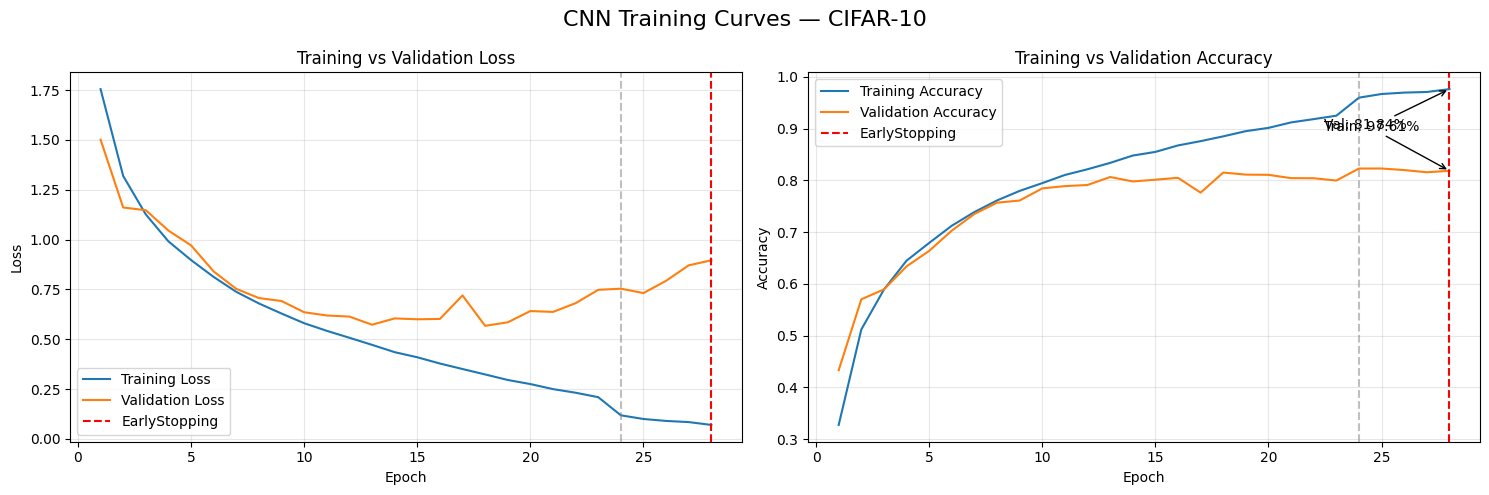

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# -------------------------
# Loss
# -------------------------

axes[0].plot(
    epochs_range,
    train_loss,
    label="Training Loss"
)

axes[0].plot(
    epochs_range,
    val_loss,
    label="Validation Loss"
)

if es.stopped_epoch > 0:
    axes[0].axvline(
        stopping_epoch,
        linestyle="--",
        color="red",
        label="EarlyStopping"
    )

for epoch in lr_reduction_epochs:
    axes[0].axvline(
        epoch,
        linestyle="--",
        color="grey",
        alpha=0.5
    )

axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)


# -------------------------
# Accuracy
# -------------------------

axes[1].plot(
    epochs_range,
    train_acc,
    label="Training Accuracy"
)

axes[1].plot(
    epochs_range,
    val_acc,
    label="Validation Accuracy"
)

if es.stopped_epoch > 0:
    axes[1].axvline(
        stopping_epoch,
        linestyle="--",
        color="red",
        label="EarlyStopping"
    )

for epoch in lr_reduction_epochs:
    axes[1].axvline(
        epoch,
        linestyle="--",
        color="grey",
        alpha=0.5
    )

axes[1].annotate(
    f"Train: {train_acc[-1] * 100:.2f}%",
    xy=(len(train_acc), train_acc[-1]),
    xytext=(-90, -30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

axes[1].annotate(
    f"Val: {val_acc[-1] * 100:.2f}%",
    xy=(len(val_acc), val_acc[-1]),
    xytext=(-90, 30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(
    "CNN Training Curves — CIFAR-10",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "plots/training_curves.png",
    
    bbox_inches="tight"
)

plt.show()

# A4.4 — Evaluate and Analyze CNN

## Evaluate Test Dataset

In [54]:
test_loss, test_accuracy = model_cnn.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

print("\nCNN Test Results")
print("=" * 40)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8033 - loss: 0.6108

CNN Test Results
Test Loss     : 0.6108
Test Accuracy : 0.8033
Test Accuracy : 80.33%


## Generate Predictions

In [55]:
y_pred_prob = model_cnn.predict(
    X_test,
    verbose=1
)

y_pred = np.argmax(
    y_pred_prob,
    axis=1
)

y_true = y_test.flatten()

print("Predictions shape:", y_pred.shape)
print("True labels shape:", y_true.shape)

print("\nFirst 10 true labels:")
print(y_true[:10])

print("\nFirst 10 predictions:")
print(y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
Predictions shape: (10000,)
True labels shape: (10000,)

First 10 true labels:
[3 8 8 0 6 6 1 6 3 1]

First 10 predictions:
[3 8 8 0 6 6 1 6 3 1]


## Import Confusion Matrix

In [56]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion Matrix Shape:", cm.shape)
print(cm)

Confusion Matrix Shape: (10, 10)
[[851  13  35  11  13   3   6   8  40  20]
 [ 13 922   0   2   0   2   0   1   8  52]
 [ 50   2 690  70  66  44  47  10   3  18]
 [ 20   7  49 671  63 106  43  16   5  20]
 [ 16   2  41  48 806  18  23  40   4   2]
 [  9   1  26 158  41 707  11  32   3  12]
 [  6   6  21  72  37  21 818   3   6  10]
 [ 10   3  17  33  62  45   3 810   5  12]
 [ 61  18   9   6   6   2   2   0 870  26]
 [ 23  64   1   8   1   1   2   2  10 888]]


## Plot 10×10 Confusion Matrix

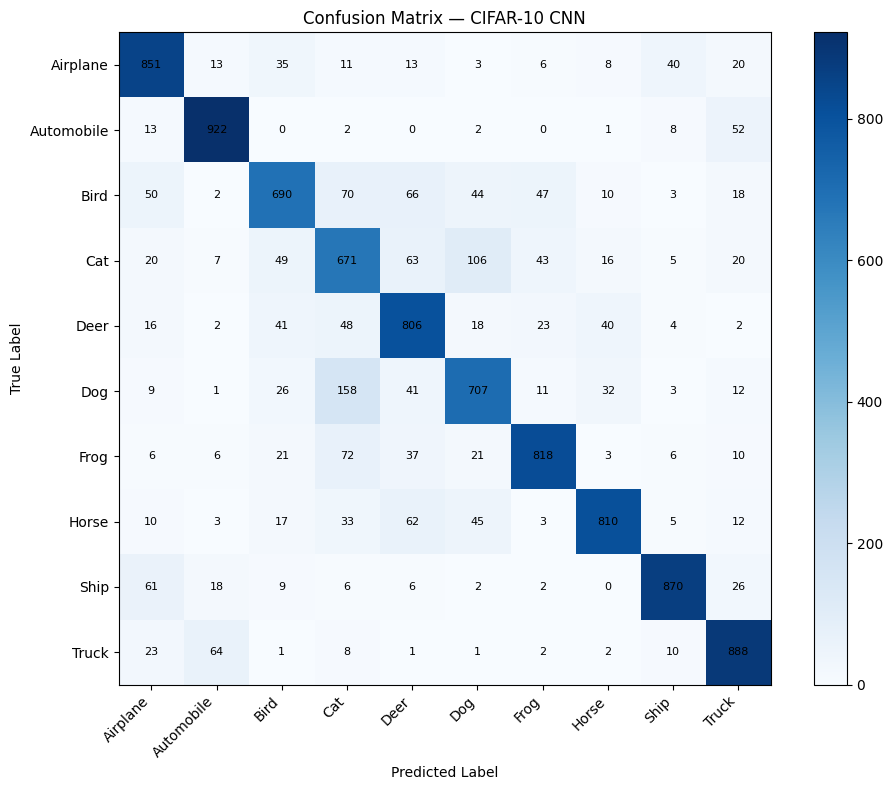

In [57]:
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm, cmap="Blues")

plt.colorbar(im, ax=ax)

ax.set_xticks(np.arange(10))
ax.set_yticks(np.arange(10))

ax.set_xticklabels(
    class_names,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(class_names)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

ax.set_title(
    "Confusion Matrix — CIFAR-10 CNN"
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()

plt.savefig(
    "plots/confusion_matrix.png",

    bbox_inches="tight"
)

plt.show()

# Identify Top 3 Most-Confused Class Pairs

## Calculate Top Confusions

In [58]:
confused_pairs = []

for i in range(len(class_names)):
    for j in range(i + 1, len(class_names)):

        total_confusion = cm[i, j] + cm[j, i]

        confused_pairs.append(
            (
                total_confusion,
                class_names[i],
                class_names[j],
                cm[i, j],
                cm[j, i]
            )
        )

confused_pairs.sort(
    key=lambda x: x[0],
    reverse=True
)

top_3_confusions = confused_pairs[:3]

print("Top 3 Most-Confused Class Pairs")
print("=" * 55)

for rank, pair in enumerate(top_3_confusions, start=1):

    total, class1, class2, c1_to_c2, c2_to_c1 = pair

    print(
        f"{rank}. {class1} ↔ {class2}"
    )

    print(
        f"   {class1} predicted as {class2}: {c1_to_c2}"
    )

    print(
        f"   {class2} predicted as {class1}: {c2_to_c1}"
    )

    print(
        f"   Total confusion: {total}\n"
    )

Top 3 Most-Confused Class Pairs
1. Cat ↔ Dog
   Cat predicted as Dog: 106
   Dog predicted as Cat: 158
   Total confusion: 264

2. Bird ↔ Cat
   Bird predicted as Cat: 70
   Cat predicted as Bird: 49
   Total confusion: 119

3. Automobile ↔ Truck
   Automobile predicted as Truck: 52
   Truck predicted as Automobile: 64
   Total confusion: 116



# Display 10 Misclassified Images

## Find Misclassified Images

In [59]:
misclassified_indices = np.where(
    y_pred != y_true
)[0]

print(
    "Total misclassified test images:",
    len(misclassified_indices)
)

print(
    "Total correctly classified test images:",
    len(y_true) - len(misclassified_indices)
)

Total misclassified test images: 1967
Total correctly classified test images: 8033


## Display 10 Misclassified Images

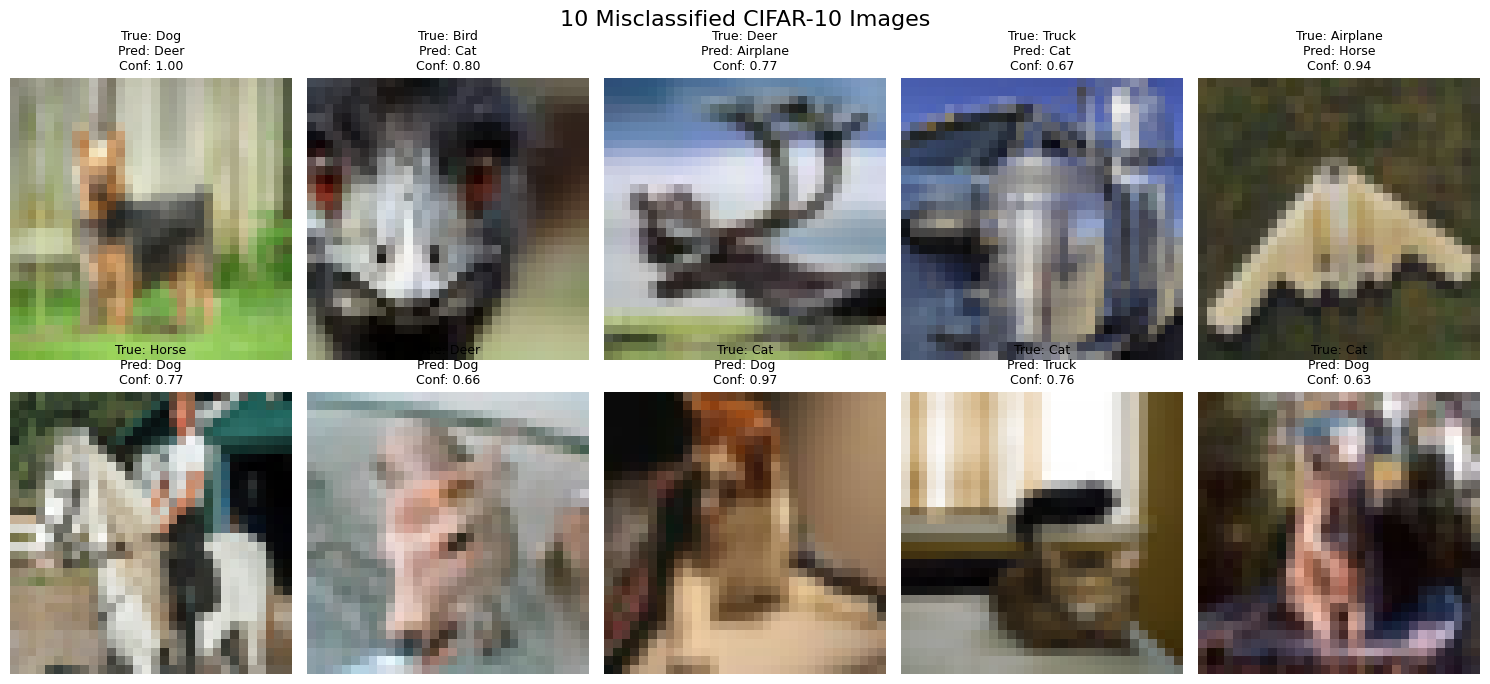

In [60]:
plt.figure(figsize=(15, 7))

for i, idx in enumerate(misclassified_indices[:10]):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[idx])

    true_name = class_names[y_true[idx]]
    predicted_name = class_names[y_pred[idx]]

    confidence = y_pred_prob[idx][y_pred[idx]]

    plt.title(
        f"True: {true_name}\n"
        f"Pred: {predicted_name}\n"
        f"Conf: {confidence:.2f}",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle(
    "10 Misclassified CIFAR-10 Images",
    fontsize=16
)

plt.suptitle(
    "10 Misclassified CIFAR-10 Images",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "plots/misclassified_images.png",
    
    bbox_inches="tight"
)

plt.show()

## Analysis of Misclassifications

The CNN can confuse visually similar CIFAR-10 classes such as **Cat vs Dog**
and **Automobile vs Truck** more easily than visually distinct categories.

One important reason is the low resolution of CIFAR-10 images.

Each image contains only:

32 × 32 pixels

At this small resolution, fine visual details that distinguish similar objects
are compressed or lost.

For example, cats and dogs can have similar shapes, textures and backgrounds.
Similarly, automobiles and trucks share features such as wheels, windows,
roads and similar overall structures.

More visually distinct categories can be easier to separate because their
overall shapes and visual patterns differ more strongly.

The confusion matrix and misclassified-image grid help identify where the
trained CNN makes these mistakes.

# Task A5: Data Augmentation

## Objective
Apply data augmentation to CIFAR-10 images to reduce overfitting and improve
the generalization ability of the CNN.

## Expected Output
- Understand why data augmentation is useful
- Create an ImageDataGenerator
- Visualize 9 augmented versions of one CIFAR-10 image
- Retrain the CNN using augmented images
- Compare training with and without augmentation
- Implement modern augmentation using Keras preprocessing layers
- Compare test accuracies

## Why Data Augmentation?

A CNN with many trainable parameters can memorize the training dataset,
which can lead to overfitting.

Data augmentation artificially increases the effective size and diversity of
the training dataset by applying random transformations to images during
training.

This means the model can see a slightly different version of the same image
during different epochs.

Common transformations include:

- Rotation
- Horizontal shifting
- Vertical shifting
- Horizontal flipping
- Zooming

Data augmentation acts as a strong regularizer and reduces overfitting
without requiring additional real-world training images.

It is especially useful for relatively small image datasets and is a standard
practice in production computer vision systems.

# A5.2 — ImageDataGenerator

## Import ImageDataGenerator

In [61]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("ImageDataGenerator imported successfully.")

ImageDataGenerator imported successfully.


## Create Data Augmentation Generator

In [62]:
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode="nearest"
)

datagen.fit(X_train)

print("ImageDataGenerator created successfully.")

ImageDataGenerator created successfully.


## Select One Training Image

Image shape: (32, 32, 3)
Class: Frog


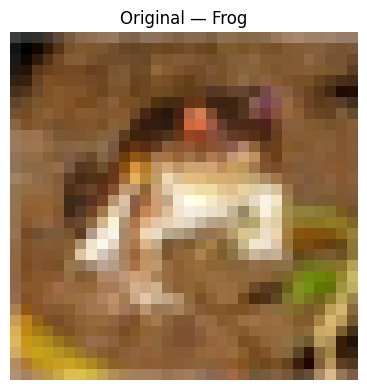

In [63]:
sample_idx = 0

img_aug = X_train[sample_idx]

print("Image shape:", img_aug.shape)
print(
    "Class:",
    class_names[y_train[sample_idx][0]]
)

plt.figure(figsize=(4, 4))
plt.imshow(img_aug)
plt.title(
    f"Original — {class_names[y_train[sample_idx][0]]}"
)
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "plots/original_image_before_augmentation.png",
    
    bbox_inches="tight"
)



## Generate 9 Augmented Images

In [64]:
augmented_images = []

generator = datagen.flow(
    img_aug[np.newaxis, ...],
    batch_size=1
)

for i in range(9):
    augmented_img = next(generator)[0]
    augmented_images.append(augmented_img)

print("Number of augmented images:", len(augmented_images))

Number of augmented images: 9


## Original + 9 Augmented Images

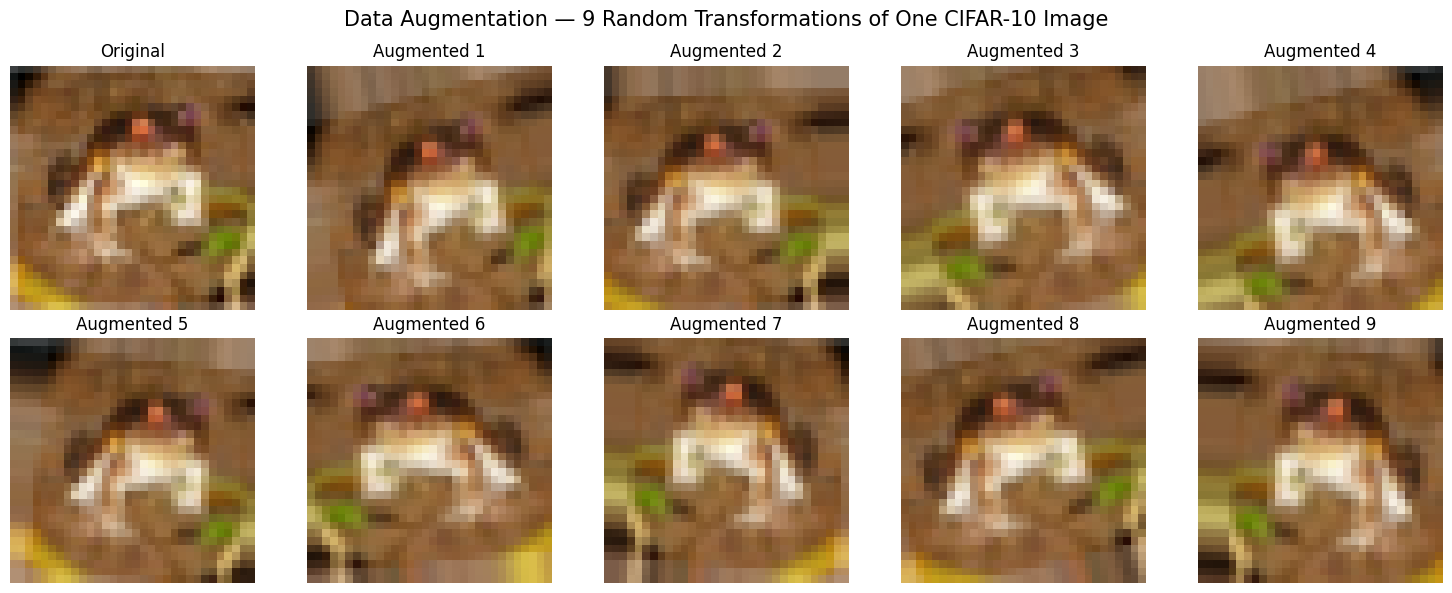

In [65]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Original image
axes[0, 0].imshow(img_aug)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

# 9 augmented images
for i in range(9):

    row = (i + 1) // 5
    col = (i + 1) % 5

    axes[row, col].imshow(
        np.clip(augmented_images[i], 0, 1)
    )

    axes[row, col].set_title(
        f"Augmented {i + 1}"
    )

    axes[row, col].axis("off")



plt.suptitle(
    "Data Augmentation — 9 Random Transformations of One CIFAR-10 Image",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "plots/augmentation_grid.png",
    
    bbox_inches="tight"
)

plt.show()

# A5.3 — Retrain CNN with Augmentation

## Build Same CNN Again

In [66]:
model_aug = keras.Sequential([

    keras.Input(shape=(32, 32, 3)),

    # Block 1
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dense(
        10,
        activation="softmax"
    )
])

model_aug.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

## Compile Augmented Model

In [67]:
model_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN compiled successfully.")

Augmented CNN compiled successfully.


## Create Fresh Callbacks

In [68]:
es_aug = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

rlrop_aug = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

print("Callbacks created.")

Callbacks created.


## Create Explicit Training/Validation Split

In [69]:
split_index = int(len(X_train) * 0.9)

X_train_aug = X_train[:split_index]
y_train_aug = y_train_ohe[:split_index]

X_val_aug = X_train[split_index:]
y_val_aug = y_train_ohe[split_index:]

print("Training images  :", X_train_aug.shape)
print("Training labels  :", y_train_aug.shape)

print("Validation images:", X_val_aug.shape)
print("Validation labels:", y_val_aug.shape)

Training images  : (45000, 32, 32, 3)
Training labels  : (45000, 10)
Validation images: (5000, 32, 32, 3)
Validation labels: (5000, 10)


## Train with ImageDataGenerator

In [70]:
history_aug = model_aug.fit(
    datagen.flow(
        X_train_aug,
        y_train_aug,
        batch_size=64
    ),
    epochs=100,
    validation_data=(
        X_val_aug,
        y_val_aug
    ),
    callbacks=[
        es_aug,
        rlrop_aug
    ],
    verbose=1
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 60s 82ms/step - accuracy: 0.3133 - loss: 1.7962 - val_accuracy: 0.3938 - val_loss: 1.6508 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 54s 77ms/step - accuracy: 0.4641 - loss: 1.4554 - val_accuracy: 0.5372 - val_loss: 1.2532 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 53s 75ms/step - accuracy: 0.5287 - loss: 1.2896 - val_accuracy: 0.5640 - val_loss: 1.2014 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 53s 75ms/step - accuracy: 0.5754 - loss: 1.1706 - val_accuracy: 0.6122 - val_loss: 1.0807 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 53s 75ms/step - accuracy: 0.6137 - loss: 1.0815 - val_accuracy: 0.6520 - val_loss: 0.9969 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 54s 76ms/step - accuracy: 0.6397 - loss: 1.0089 - val_accuracy: 0.6372 - val_loss: 1.0909 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 62s 88ms/step - accuracy: 0.6

## Evaluate Augmented CNN

In [71]:
aug_test_loss, aug_test_accuracy = model_aug.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

print("\nCNN + ImageDataGenerator")
print("=" * 40)

print(
    f"Test Loss     : {aug_test_loss:.4f}"
)

print(
    f"Test Accuracy : {aug_test_accuracy * 100:.2f}%"
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8461 - loss: 0.4891

CNN + ImageDataGenerator
Test Loss     : 0.4891
Test Accuracy : 84.61%


# Compare No Augmentation vs Augmentation

## Print Accuracy Comparison

In [72]:
print("TEST ACCURACY COMPARISON")
print("=" * 50)

print(
    f"CNN without augmentation : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"CNN with augmentation    : "
    f"{aug_test_accuracy * 100:.2f}%"
)

difference = (
    aug_test_accuracy - test_accuracy
) * 100

print(
    f"\nAccuracy difference       : "
    f"{difference:+.2f} percentage points"
)

TEST ACCURACY COMPARISON
CNN without augmentation : 80.33%
CNN with augmentation    : 84.61%

Accuracy difference       : +4.28 percentage points


## Prepare Histories

In [73]:
epochs_no_aug = range(
    1,
    len(history.history["accuracy"]) + 1
)

epochs_aug = range(
    1,
    len(history_aug.history["accuracy"]) + 1
)

print(
    "No augmentation epochs:",
    len(history.history["accuracy"])
)

print(
    "Augmentation epochs:",
    len(history_aug.history["accuracy"])
)

No augmentation epochs: 28
Augmentation epochs: 60


## Compare Training Curves

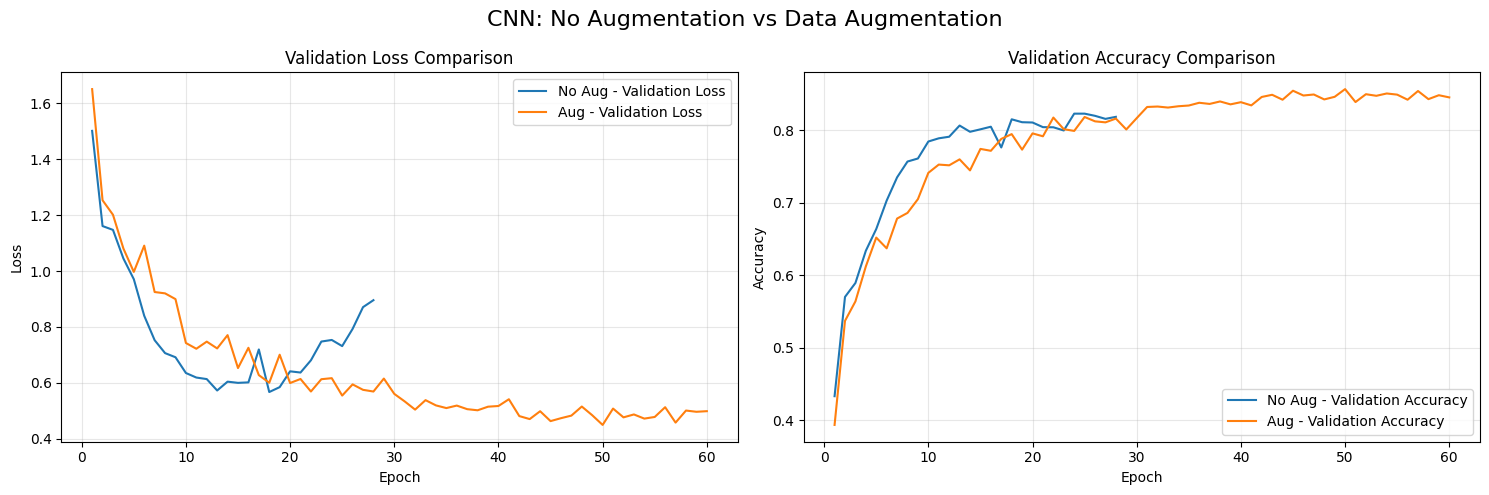

In [74]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

# --------------------------------
# LOSS
# --------------------------------

axes[0].plot(
    epochs_no_aug,
    history.history["val_loss"],
    label="No Aug - Validation Loss"
)

axes[0].plot(
    epochs_aug,
    history_aug.history["val_loss"],
    label="Aug - Validation Loss"
)

axes[0].set_title(
    "Validation Loss Comparison"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)


# --------------------------------
# ACCURACY
# --------------------------------

axes[1].plot(
    epochs_no_aug,
    history.history["val_accuracy"],
    label="No Aug - Validation Accuracy"
)

axes[1].plot(
    epochs_aug,
    history_aug.history["val_accuracy"],
    label="Aug - Validation Accuracy"
)

axes[1].set_title(
    "Validation Accuracy Comparison"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "CNN: No Augmentation vs Data Augmentation",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "plots/augmentation_validation_comparison.png",
    
    bbox_inches="tight"
)

plt.show()

## Required 4-Line Accuracy Comparison

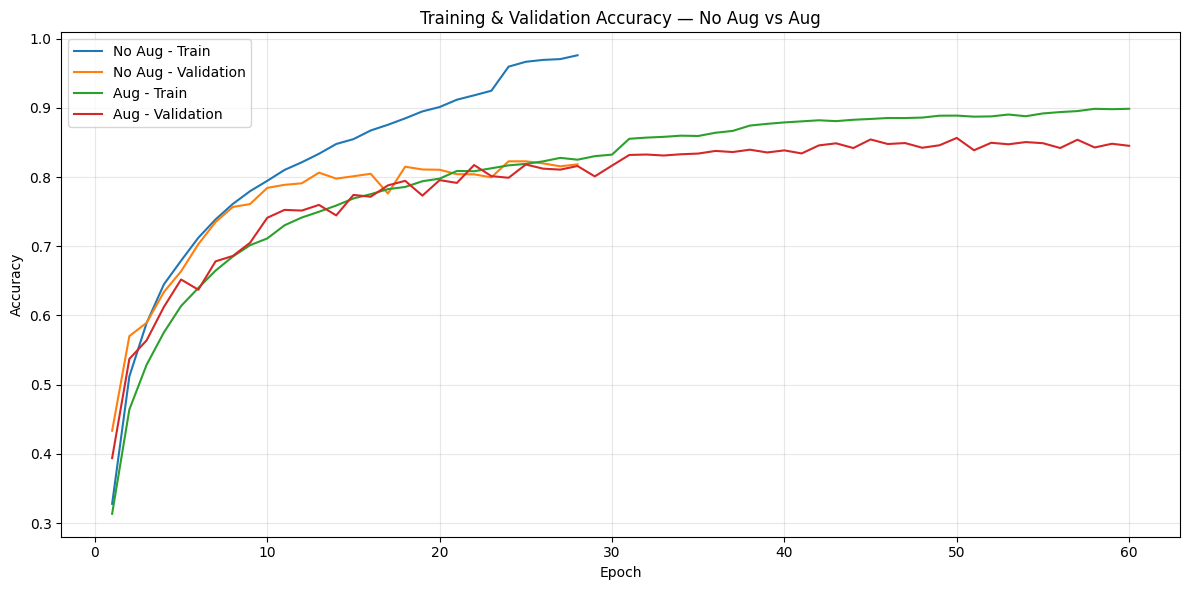

In [75]:
plt.figure(figsize=(12, 6))

# No augmentation
plt.plot(
    epochs_no_aug,
    history.history["accuracy"],
    label="No Aug - Train"
)

plt.plot(
    epochs_no_aug,
    history.history["val_accuracy"],
    label="No Aug - Validation"
)

# With augmentation
plt.plot(
    epochs_aug,
    history_aug.history["accuracy"],
    label="Aug - Train"
)

plt.plot(
    epochs_aug,
    history_aug.history["val_accuracy"],
    label="Aug - Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Training & Validation Accuracy — No Aug vs Aug"
)

plt.legend()
plt.grid(alpha=0.3)


plt.tight_layout()

plt.savefig(
    "plots/augmentation_accuracy_comparison.png",
    bbox_inches="tight"
)

plt.show()

### Effect of Data Augmentation

The augmented CNN is trained on randomly transformed versions of the
original training images.

This makes the training task more difficult, so training accuracy may be
slightly lower than the model trained without augmentation.

However, augmentation can reduce the gap between training and validation
accuracy.

A smaller gap indicates less overfitting and better generalization.

The final test accuracies should be compared to determine whether
augmentation improved performance on unseen CIFAR-10 images.

# A5.4 — Modern Augmentation with Keras Layers

## Create Modern Augmentation Pipeline

In [76]:
data_augmentation = keras.Sequential([
    
    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.1
    ),

    layers.RandomZoom(
        0.1
    ),

    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )

], name="data_augmentation")

print("Modern Keras augmentation pipeline created.")

Modern Keras augmentation pipeline created.


## Visualize Modern Augmentation

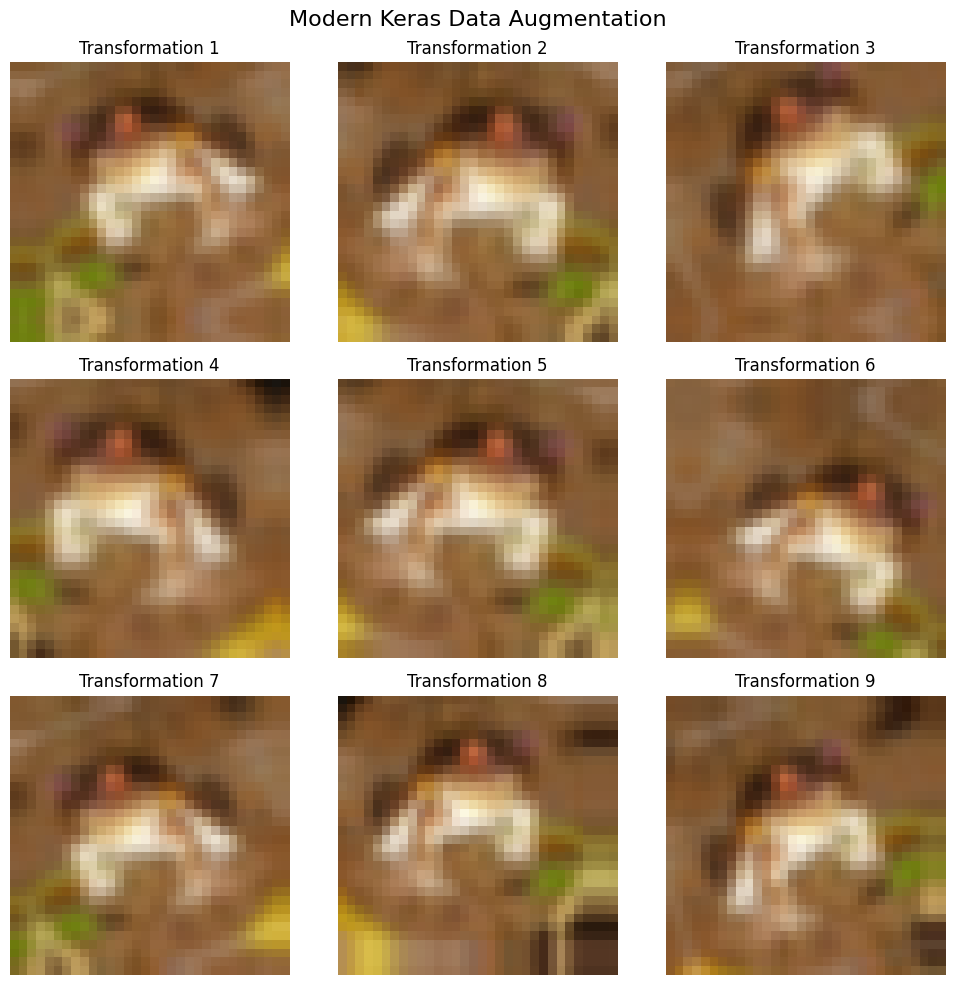

In [77]:
plt.figure(figsize=(10, 10))

for i in range(9):

    augmented = data_augmentation(
        img_aug[np.newaxis, ...],
        training=True
    )

    plt.subplot(3, 3, i + 1)

    plt.imshow(
        np.clip(augmented[0].numpy(), 0, 1)
    )

    plt.title(
        f"Transformation {i + 1}"
    )

    plt.axis("off")



plt.suptitle(
    "Modern Keras Data Augmentation",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "plots/keras_augmentation_grid.png",
    
    bbox_inches="tight"
)

plt.show()

## Build CNN with Keras Augmentation Layers

In [78]:
model_keras_aug = keras.Sequential([

    keras.Input(shape=(32, 32, 3)),

    # Augmentation
    data_augmentation,

    # CNN Block 1
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # CNN Block 2
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # CNN Block 3
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dense(
        10,
        activation="softmax"
    )
])

model_keras_aug.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

## Compile Model

In [79]:
model_keras_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "CNN with Keras augmentation layers compiled successfully."
)

CNN with Keras augmentation layers compiled successfully.


## Fresh Callbacks

In [80]:
es_keras_aug = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

rlrop_keras_aug = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

## Train Modern Augmented CNN

In [81]:
history_keras_aug = model_keras_aug.fit(
    X_train,
    y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        es_keras_aug,
        rlrop_keras_aug
    ],
    verbose=1
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 59s 77ms/step - accuracy: 0.3017 - loss: 1.8474 - val_accuracy: 0.3686 - val_loss: 1.7253 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 50s 71ms/step - accuracy: 0.4312 - loss: 1.5435 - val_accuracy: 0.4796 - val_loss: 1.4767 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.4918 - loss: 1.3945 - val_accuracy: 0.4630 - val_loss: 1.5371 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.5344 - loss: 1.2921 - val_accuracy: 0.5374 - val_loss: 1.3007 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.5633 - loss: 1.2199 - val_accuracy: 0.5726 - val_loss: 1.2587 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.5826 - loss: 1.1715 - val_accuracy: 0.6110 - val_loss: 1.1263 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.5

## Evaluate Modern Keras Augmentation Model

In [82]:
keras_aug_loss, keras_aug_accuracy = model_keras_aug.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

print("\nCNN + Keras Augmentation Layers")
print("=" * 45)

print(
    f"Test Loss     : {keras_aug_loss:.4f}"
)

print(
    f"Test Accuracy : {keras_aug_accuracy * 100:.2f}%"
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.7989 - loss: 0.6734

CNN + Keras Augmentation Layers
Test Loss     : 0.6734
Test Accuracy : 79.89%


## Final A5 Comparison

In [83]:
comparison_a5 = pd.DataFrame({

    "Model": [
        "CNN - No Augmentation",
        "CNN - ImageDataGenerator",
        "CNN - Keras Augmentation Layers"
    ],

    "Test Accuracy": [
        test_accuracy,
        aug_test_accuracy,
        keras_aug_accuracy
    ]
})

comparison_a5["Test Accuracy (%)"] = (
    comparison_a5["Test Accuracy"] * 100
).round(2)

comparison_a5[
    ["Model", "Test Accuracy (%)"]
]

,Model,Test Accuracy (%)
0,CNN - No Augmentation,80.33
1,CNN - ImageDataGenerator,84.61
2,CNN - Keras Augmentation Layers,79.89


## Task A5 Conclusion

Three versions of the custom CNN were evaluated:

1. CNN without augmentation
2. CNN with ImageDataGenerator
3. CNN with modern Keras preprocessing augmentation layers

ImageDataGenerator performs random transformations before images are passed
to the CNN.

Modern Keras augmentation layers perform augmentation directly inside the
model during training and automatically become inactive during inference.

Data augmentation can reduce overfitting by exposing the model to different
variations of the training images.

The final test accuracy values should be used to determine which approach
generalized best on the unseen CIFAR-10 test dataset.

# Task A6: Transfer Learning — Feature Extraction & Fine-Tuning

## Objective
Use MobileNetV2 pre-trained on ImageNet to perform transfer learning on
CIFAR-10 using feature extraction and fine-tuning.

## Expected Output
- Understand Transfer Learning
- Resize CIFAR-10 images from 32×32 to 96×96
- Load pre-trained MobileNetV2
- Perform Feature Extraction
- Fine-tune the top 30 MobileNetV2 layers
- Compare Feature Extraction and Fine-Tuning
- Create a complete model comparison table
- Demonstrate a residual connection using Functional API

## Why Transfer Learning?

Training a deep CNN from scratch can require a large amount of data,
computational resources and training time.

Transfer Learning uses a neural network that has already been trained on a
large dataset and adapts its learned knowledge to a new problem.

In this task, MobileNetV2 pre-trained on ImageNet is used.

The pre-trained network has already learned useful visual features such as:

- Edges
- Textures
- Shapes
- Object parts

These learned features can also be useful for CIFAR-10 classification.

### Two Transfer Learning Strategies

#### 1. Feature Extraction

The pre-trained MobileNetV2 layers are frozen.

Their weights are not updated during training.

A new classification head is added and only this new head is trained.

This approach is faster because relatively few parameters need to be
updated.

#### 2. Fine-Tuning

Some of the upper layers of the pre-trained model are unfrozen.

These layers are then trained together with the new classification head
using a very small learning rate.

Fine-tuning allows the pre-trained features to adapt more specifically to
the CIFAR-10 dataset.

# A6.2 — Feature Extraction with MobileNetV2

## Load MobileNetV2

In [84]:
base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully.")
print("Base model trainable:", base_model.trainable)

MobileNetV2 loaded successfully.
Base model trainable: False


## Demonstrate Required Resize

In [85]:
sample_resized = tf.image.resize(
    X_train[:5],
    (96, 96)
)

print("Original shape:", X_train[:5].shape)
print("Resized shape :", sample_resized.shape)

Original shape: (5, 32, 32, 3)
Resized shape : (5, 96, 96, 3)


## Build Feature Extraction Model

In [86]:
inputs = keras.Input(
    shape=(32, 32, 3),
    name="cifar10_input"
)

# Resize CIFAR-10 images for MobileNetV2
x = layers.Resizing(
    96,
    96,
    name="resize_to_96"
)(inputs)

# Frozen MobileNetV2
x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

outputs = layers.Dense(
    10,
    activation="softmax"
)(x)

model_fe = keras.Model(
    inputs,
    outputs,
    name="MobileNetV2_Feature_Extraction"
)

model_fe.summary()

Model: "MobileNetV2_Feature_Extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cifar10_input (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize_to_96 (Resizing)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Total vs Trainable Parameters

In [87]:
total_params_fe = model_fe.count_params()

trainable_params_fe = sum(
    np.prod(v.shape)
    for v in model_fe.trainable_weights
)

non_trainable_params_fe = sum(
    np.prod(v.shape)
    for v in model_fe.non_trainable_weights
)

print("FEATURE EXTRACTION PARAMETERS")
print("=" * 45)

print(
    "Total parameters       :",
    f"{total_params_fe:,}"
)

print(
    "Trainable parameters   :",
    f"{trainable_params_fe:,}"
)

print(
    "Non-trainable parameters:",
    f"{non_trainable_params_fe:,}"
)

print(
    "\nMobileNetV2 trainable:",
    base_model.trainable
)

FEATURE EXTRACTION PARAMETERS
Total parameters       : 2,423,242
Trainable parameters   : 165,258
Non-trainable parameters: 2,257,984

MobileNetV2 trainable: False


# A6.3 — Train Feature Extraction Model

## Compile

In [88]:
model_fe.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Feature Extraction model compiled.")

Feature Extraction model compiled.


## Train for 20 Epochs

In [89]:
history_fe = model_fe.fit(
    X_train,
    y_train_ohe,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 209s 283ms/step - accuracy: 0.7480 - loss: 0.7305 - val_accuracy: 0.7626 - val_loss: 0.6805
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 203s 288ms/step - accuracy: 0.8067 - loss: 0.5544 - val_accuracy: 0.7926 - val_loss: 0.5976
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 378s 537ms/step - accuracy: 0.8250 - loss: 0.4993 - val_accuracy: 0.8044 - val_loss: 0.5549
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 154s 219ms/step - accuracy: 0.8391 - loss: 0.4563 - val_accuracy: 0.8024 - val_loss: 0.5712
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 159s 225ms/step - accuracy: 0.8513 - loss: 0.4197 - val_accuracy: 0.8054 - val_loss: 0.5608
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 160s 227ms/step - accuracy: 0.8665 - loss: 0.3816 - val_accuracy: 0.8148 - val_loss: 0.5544
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 153s 218ms/step - accuracy: 0.8771 - loss: 0.3453 - val_accuracy: 0.8104 - val_loss: 0.5730
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 157s 223ms/step - accuracy: 0.8882 -

## Evaluate Feature Extraction

In [90]:
fe_test_loss, fe_test_accuracy = model_fe.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

print("\nMobileNetV2 Feature Extraction")
print("=" * 45)

print(
    f"Test Loss     : {fe_test_loss:.4f}"
)

print(
    f"Test Accuracy : {fe_test_accuracy * 100:.2f}%"
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 112ms/step - accuracy: 0.7941 - loss: 1.0210

MobileNetV2 Feature Extraction
Test Loss     : 1.0210
Test Accuracy : 79.41%


# A6.4 — Fine-Tuning

## Unfreeze Top 30 Layers

In [91]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

print(
    "Total MobileNetV2 layers:",
    len(base_model.layers)
)

print(
    "Trainable MobileNetV2 layers:",
    sum(layer.trainable for layer in base_model.layers)
)

print(
    "Frozen MobileNetV2 layers:",
    sum(not layer.trainable for layer in base_model.layers)
)

Total MobileNetV2 layers: 154
Trainable MobileNetV2 layers: 30
Frozen MobileNetV2 layers: 124


## Display Last 30 Layers

In [92]:
print("LAST 30 MOBILENETV2 LAYERS")
print("=" * 60)

for layer in base_model.layers[-30:]:

    print(
        f"{layer.name:40s} "
        f"Trainable = {layer.trainable}"
    )

LAST 30 MOBILENETV2 LAYERS
block_13_project_BN                      Trainable = True
block_14_expand                          Trainable = True
block_14_expand_BN                       Trainable = True
block_14_expand_relu                     Trainable = True
block_14_depthwise                       Trainable = True
block_14_depthwise_BN                    Trainable = True
block_14_depthwise_relu                  Trainable = True
block_14_project                         Trainable = True
block_14_project_BN                      Trainable = True
block_14_add                             Trainable = True
block_15_expand                          Trainable = True
block_15_expand_BN                       Trainable = True
block_15_expand_relu                     Trainable = True
block_15_depthwise                       Trainable = True
block_15_depthwise_BN                    Trainable = True
block_15_depthwise_relu                  Trainable = True
block_15_project                         Trai

## Recompile with Very Low Learning Rate

In [93]:
model_fe.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "Model recompiled for fine-tuning."
)

print(
    "Fine-tuning learning rate = 1e-5"
)

Model recompiled for fine-tuning.
Fine-tuning learning rate = 1e-5


## Fine-Tune for 10 Epochs

In [94]:
history_ft = model_fe.fit(
    X_train,
    y_train_ohe,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 236s 162ms/step - accuracy: 0.6879 - loss: 2.9111 - val_accuracy: 0.7712 - val_loss: 1.6959
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 199s 142ms/step - accuracy: 0.7700 - loss: 1.6181 - val_accuracy: 0.7698 - val_loss: 1.6479
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 206s 146ms/step - accuracy: 0.7976 - loss: 1.1325 - val_accuracy: 0.7756 - val_loss: 1.4854
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 206s 147ms/step - accuracy: 0.8214 - loss: 0.8715 - val_accuracy: 0.7870 - val_loss: 1.3081
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 204s 143ms/step - accuracy: 0.8400 - loss: 0.6732 - val_accuracy: 0.7912 - val_loss: 1.1904
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 207s 147ms/step - accuracy: 0.8569 - loss: 0.5484 - val_accuracy: 0.7954 - val_loss: 1.1003
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 210s 149ms/step - accuracy: 0.8694 - loss: 0.4564 - val_accuracy: 0.8028 - val_loss: 1.0232
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 214s 152ms/step - ac

## Evaluate Fine-Tuned Model

In [95]:
ft_test_loss, ft_test_accuracy = model_fe.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

print("\nMobileNetV2 Fine-Tuned")
print("=" * 40)

print(
    f"Test Loss     : {ft_test_loss:.4f}"
)

print(
    f"Test Accuracy : {ft_test_accuracy * 100:.2f}%"
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 33s 105ms/step - accuracy: 0.8083 - loss: 0.9924

MobileNetV2 Fine-Tuned
Test Loss     : 0.9924
Test Accuracy : 80.83%


### Why Use a Low Learning Rate for Fine-Tuning?

The pre-trained MobileNetV2 weights already contain useful visual knowledge
learned from ImageNet.

A large learning rate could make large changes to these weights and destroy
the useful features that have already been learned.

Therefore, fine-tuning uses a very small learning rate:

`1e-5`

This gently adjusts the upper pre-trained layers toward the CIFAR-10
classification task without drastically changing the existing useful
representations.

# Feature Extraction + Fine-Tuning Curves

## Concatenate Histories

In [96]:
fe_acc = history_fe.history["accuracy"]
fe_val_acc = history_fe.history["val_accuracy"]

fe_loss = history_fe.history["loss"]
fe_val_loss = history_fe.history["val_loss"]


ft_acc = history_ft.history["accuracy"]
ft_val_acc = history_ft.history["val_accuracy"]

ft_loss = history_ft.history["loss"]
ft_val_loss = history_ft.history["val_loss"]


combined_acc = fe_acc + ft_acc
combined_val_acc = fe_val_acc + ft_val_acc

combined_loss = fe_loss + ft_loss
combined_val_loss = fe_val_loss + ft_val_loss


fine_tune_start = len(fe_acc)

epochs_combined = range(
    1,
    len(combined_acc) + 1
)

print(
    "Feature Extraction epochs:",
    len(fe_acc)
)

print(
    "Fine-Tuning epochs:",
    len(ft_acc)
)

print(
    "Fine-Tuning starts after epoch:",
    fine_tune_start
)

Feature Extraction epochs: 20
Fine-Tuning epochs: 10
Fine-Tuning starts after epoch: 20


## Plot Combined Training Curves

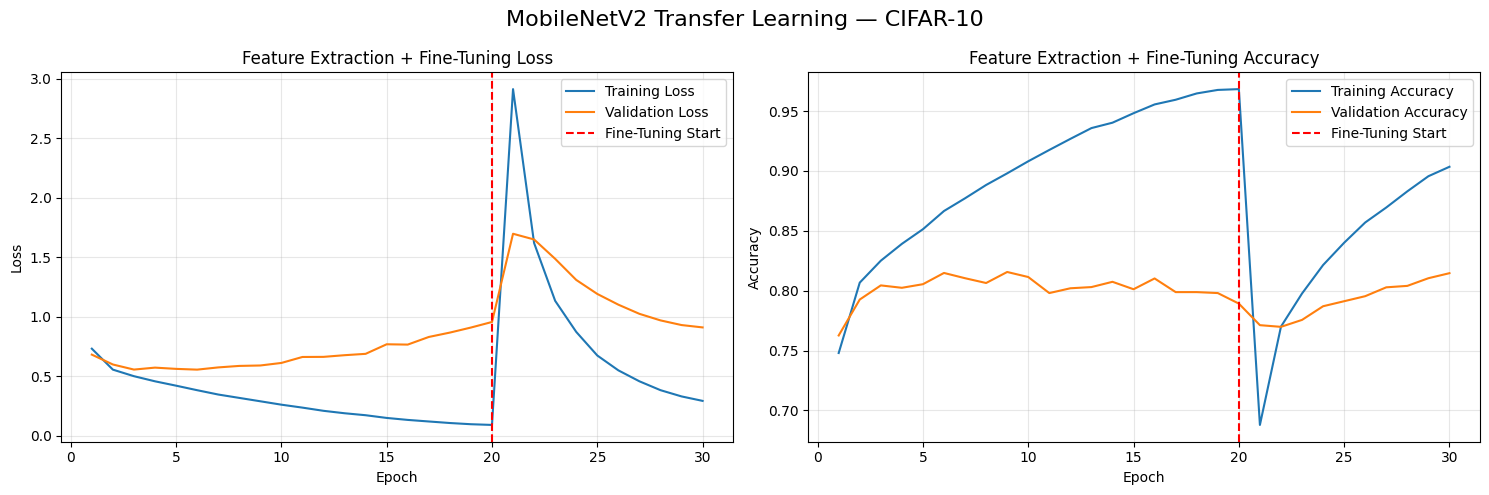

In [97]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

# LOSS
axes[0].plot(
    epochs_combined,
    combined_loss,
    label="Training Loss"
)

axes[0].plot(
    epochs_combined,
    combined_val_loss,
    label="Validation Loss"
)

axes[0].axvline(
    fine_tune_start,
    linestyle="--",
    color="red",
    label="Fine-Tuning Start"
)

axes[0].set_title(
    "Feature Extraction + Fine-Tuning Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)


# ACCURACY
axes[1].plot(
    epochs_combined,
    combined_acc,
    label="Training Accuracy"
)

axes[1].plot(
    epochs_combined,
    combined_val_acc,
    label="Validation Accuracy"
)

axes[1].axvline(
    fine_tune_start,
    linestyle="--",
    color="red",
    label="Fine-Tuning Start"
)

axes[1].set_title(
    "Feature Extraction + Fine-Tuning Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "MobileNetV2 Transfer Learning — CIFAR-10",
    fontsize=16
)

plt.tight_layout()
plt.show()

# A6.5 — Full Results Comparison Table

## Compile LeNet-5

In [98]:
model_lenet.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("LeNet-5 compiled successfully.")

LeNet-5 compiled successfully.


## Train LeNet-5

In [99]:
history_lenet = model_lenet.fit(
    X_train,
    y_train_ohe,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.3562 - loss: 1.8135 - val_accuracy: 0.3936 - val_loss: 1.7160
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4226 - loss: 1.6364 - val_accuracy: 0.4470 - val_loss: 1.5790
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.4665 - loss: 1.5103 - val_accuracy: 0.4690 - val_loss: 1.4941
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4920 - loss: 1.4331 - val_accuracy: 0.4922 - val_loss: 1.4447
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5135 - loss: 1.3737 - val_accuracy: 0.5182 - val_loss: 1.3850
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5297 - loss: 1.3244 - val_accuracy: 0.5112 - val_loss: 1.3966
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5461 - loss: 1.2817 - val_accuracy: 0.5260 - val_loss: 1.3612
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5598 - loss: 1.2440 - val_accuracy: 0.

## Evaluate LeNet-5

In [100]:
lenet_test_loss, lenet_test_accuracy = model_lenet.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

print(
    f"LeNet-5 Test Accuracy: "
    f"{lenet_test_accuracy * 100:.2f}%"
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5345 - loss: 1.4135
LeNet-5 Test Accuracy: 53.45%


## Save Parameter Counts

In [101]:
params_lenet = model_lenet.count_params()

params_cnn = model_cnn.count_params()

params_aug = model_aug.count_params()

params_keras_aug = model_keras_aug.count_params()

params_fe = total_params_fe

params_ft = model_fe.count_params()

print("Parameter counts collected.")

Parameter counts collected.


## Create Six-Model Results Table

In [102]:
results_df = pd.DataFrame({

    "Model": [
        "LeNet-5",
        "CNN Scratch No Aug",
        "CNN Scratch + Aug",
        "CNN + Keras Aug Layers",
        "MobileNetV2 Feature Extraction",
        "MobileNetV2 Fine-Tuned"
    ],

    "Architecture": [
        "LeNet-5",
        "Custom CNN",
        "Custom CNN",
        "Custom CNN",
        "MobileNetV2",
        "MobileNetV2"
    ],

    "Augmentation": [
        "No",
        "No",
        "ImageDataGenerator",
        "Keras Layers",
        "No",
        "No"
    ],

    "Transfer Learning": [
        "No",
        "No",
        "No",
        "No",
        "Feature Extraction",
        "Fine-Tuning"
    ],

    "Test Accuracy": [
        lenet_test_accuracy,
        test_accuracy,
        aug_test_accuracy,
        keras_aug_accuracy,
        fe_test_accuracy,
        ft_test_accuracy
    ],

    "Parameters": [
        params_lenet,
        params_cnn,
        params_aug,
        params_keras_aug,
        params_fe,
        params_ft
    ]
})

results_df

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy,Parameters
0,LeNet-5,LeNet-5,No,No,0.5345,62006
1,CNN Scratch No Aug,Custom CNN,No,No,0.8033,175018
2,CNN Scratch + Aug,Custom CNN,ImageDataGenerator,No,0.8461,175018
3,CNN + Keras Aug Layers,Custom CNN,Keras Layers,No,0.7989,175018
4,MobileNetV2 Feature Extraction,MobileNetV2,No,Feature Extraction,0.7941,2423242
5,MobileNetV2 Fine-Tuned,MobileNetV2,No,Fine-Tuning,0.8083,2423242


## Format Accuracy

In [103]:
results_display = results_df.copy()

results_display["Test Accuracy"] = (
    results_display["Test Accuracy"] * 100
).round(2)

results_display["Parameters"] = (
    results_display["Parameters"]
    .apply(lambda x: f"{int(x):,}")
)

results_display

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy,Parameters
0,LeNet-5,LeNet-5,No,No,53.45,"62,006"
1,CNN Scratch No Aug,Custom CNN,No,No,80.33,"175,018"
2,CNN Scratch + Aug,Custom CNN,ImageDataGenerator,No,84.61,"175,018"
3,CNN + Keras Aug Layers,Custom CNN,Keras Layers,No,79.89,"175,018"
4,MobileNetV2 Feature Extraction,MobileNetV2,No,Feature Extraction,79.41,"2,423,242"
5,MobileNetV2 Fine-Tuned,MobileNetV2,No,Fine-Tuning,80.83,"2,423,242"


## Highlight Best Test Accuracy

In [104]:
results_display.style.highlight_max(
    subset=["Test Accuracy"]
).format({
    "Test Accuracy": "{:.2f}%"
})

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy,Parameters
0,LeNet-5,LeNet-5,No,No,53.45%,"62,006"
1,CNN Scratch No Aug,Custom CNN,No,No,80.33%,"175,018"
2,CNN Scratch + Aug,Custom CNN,ImageDataGenerator,No,84.61%,"175,018"
3,CNN + Keras Aug Layers,Custom CNN,Keras Layers,No,79.89%,"175,018"
4,MobileNetV2 Feature Extraction,MobileNetV2,No,Feature Extraction,79.41%,"2,423,242"
5,MobileNetV2 Fine-Tuned,MobileNetV2,No,Fine-Tuning,80.83%,"2,423,242"


## Find Best Model Automatically

In [105]:
best_index = results_df[
    "Test Accuracy"
].idxmax()

best_model = results_df.loc[
    best_index,
    "Model"
]

best_accuracy = results_df.loc[
    best_index,
    "Test Accuracy"
]

print("FINAL PROJECT RESULT")
print("=" * 50)

print(
    "Best Model:",
    best_model
)

print(
    f"Best Test Accuracy: "
    f"{best_accuracy * 100:.2f}%"
)

FINAL PROJECT RESULT
Best Model: CNN Scratch + Aug
Best Test Accuracy: 84.61%


## Results Comparison

The experiment compares the progression from a historical LeNet-5
architecture to a modern CNN, data augmentation and transfer learning.

LeNet-5 provides a relatively simple historical CNN baseline.

The custom CNN uses deeper convolutional feature extraction and modern
components such as ReLU, MaxPooling and GlobalAveragePooling.

Data augmentation exposes the model to random variations of the training
images and can reduce overfitting.

MobileNetV2 Feature Extraction reuses pre-trained ImageNet features while
keeping the pre-trained base frozen.

Fine-Tuning additionally allows the upper MobileNetV2 layers to adapt to
CIFAR-10 using a very small learning rate.

The final results table should be used to compare the actual accuracy and
parameter trade-offs observed during this experiment.

# A6.6 — Non-Linear Architecture: Residual Connection

## Build Residual Block

In [106]:
res_inputs = keras.Input(
    shape=(32, 32, 3),
    name="residual_input"
)

# Shortcut branch
shortcut = layers.Conv2D(
    64,
    kernel_size=(1, 1),
    padding="same",
    name="shortcut_conv"
)(res_inputs)


# Main branch
x = layers.Conv2D(
    64,
    kernel_size=(3, 3),
    activation="relu",
    padding="same",
    name="main_conv_1"
)(res_inputs)

x = layers.Conv2D(
    64,
    kernel_size=(3, 3),
    padding="same",
    name="main_conv_2"
)(x)


# Add shortcut + main branch
x = layers.Add(
    name="skip_connection"
)([x, shortcut])


# Final activation
res_outputs = layers.Activation(
    "relu",
    name="residual_relu"
)(x)


residual_model = keras.Model(
    inputs=res_inputs,
    outputs=res_outputs,
    name="Minimal_Residual_Block"
)

residual_model.summary()

Model: "Minimal_Residual_Block"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ residual_input      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ main_conv_1         │ (None, 32, 32,    │      1,792 │ residual_input[0… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ main_conv_2         │ (None, 32, 32,    │     36,928 │ main_conv_1[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shortcut_conv       │ (None, 32, 32,    │        256 │ residual_input[0… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_connection     │ (None, 32, 32,    │          0 │ main_conv_2[0][0… │
│ (Add)               │ 64)               │            │ shortcut_conv[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_relu       │ (None, 32, 32,    │          0 │ skip_connection[… │
│ (Activation)        │ 64)               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,976 (152.25 KB)

 Trainable params: 38,976 (152.25 KB)

 Non-trainable params: 0 (0.00 B)

## Test Residual Block

In [107]:
sample_batch = X_train[:1]

residual_output = residual_model.predict(
    sample_batch,
    verbose=0
)

print("Residual Block")
print("=" * 40)

print(
    "Input shape :",
    sample_batch.shape
)

print(
    "Output shape:",
    residual_output.shape
)

Residual Block
Input shape : (1, 32, 32, 3)
Output shape: (1, 32, 32, 64)


## Residual Connections and Non-Linear CNN Architectures

A standard Sequential CNN passes information through layers one after
another.

A residual network introduces skip connections, allowing information to
bypass one or more layers.

In this residual block, the input follows two paths:

### Main Path

Input
→ Conv2D(64, 3×3, ReLU)
→ Conv2D(64, 3×3)

### Shortcut Path

Input
→ Conv2D(64, 1×1)

The outputs from both paths are then added:

Main Path + Shortcut Path
→ ReLU

This creates a non-linear, non-sequential architecture.

Skip connections provide an additional path for gradients during
backpropagation.

This helps gradients propagate through very deep neural networks and reduces
the vanishing-gradient problem.

Residual connections are the core architectural innovation behind ResNet.

# Project A Completed — CNN from Scratch: CIFAR-10 Image Classifier

All six task groups have been completed:

- Task A1 — Data Loading, EDA & Preprocessing
- Task A2 — Convolution, Padding & Strides
- Task A3 — Pooling, Flatten, LeNet-5 & Custom CNN
- Task A4 — Backpropagation, Training & Evaluation
- Task A5 — Data Augmentation
- Task A6 — Transfer Learning, Fine-Tuning & Residual Connections

The project demonstrates the complete progression from basic convolution
operations to modern transfer-learning techniques for image classification.

In [108]:
import os

os.makedirs("plots", exist_ok=True)

print("plots folder is ready.")

plots folder is ready.
